# FarmTech Vision — Fase 6: O Despertar da Rede Neural

**Aluno:** Pedro Henrique do Nascimento Souza  
**RM:** 565326  
**Disciplina/atividade:** Fase 6 — O Despertar da Rede Neural

## 1. Objetivo

Este notebook apresenta o desenvolvimento e a avaliação de um projeto de visão computacional voltado à identificação de duas classes de veículos: **carros e tratores**. A proposta utiliza o modelo YOLO personalizado, com treinamentos em diferentes quantidades de épocas, e prevê a comparação com uma abordagem YOLO tradicional e uma rede neural convolucional (CNN) treinada do zero.

A primeira configuração do YOLO personalizado já foi treinada durante 30 épocas, utilizando imagens anotadas e organizadas em conjuntos de treinamento, validação e teste. Também foram realizadas a avaliação do modelo e a geração de evidências visuais das detecções. Os experimentos restantes serão desenvolvidos para permitir uma comparação crítica entre as abordagens, considerando métricas de desempenho, limitações e custo computacional.

## 2. Plano experimental e divisão dos dados

O enunciado solicita 40 imagens por classe, totalizando 80 imagens. Para cada classe, a divisão será de 32 imagens para treino, 4 para validação e 4 para teste.

| Conjunto | Tratores | Carros | Total |
|---|---:|---:|---:|
| Treino | 32 | 32 | 64 |
| Validação | 4 | 4 | 8 |
| Teste | 4 | 4 | 8 |
| **Total** | **40** | **40** | **80** |

A quantidade mínima é pequena para representar toda a variedade de veículos. Por isso, os resultados serão interpretados como um experimento acadêmico inicial, e não como evidência de desempenho em produção.

## 3. Preparação do ambiente

O ambiente experimental foi configurado no Google Colab, com integração ao Google Drive para armazenamento do dataset, dos modelos treinados e dos resultados. Foram utilizadas bibliotecas como PyTorch e Ultralytics, com aceleração por GPU NVIDIA Tesla T4. O conjunto de dados foi organizado no formato YOLO, com imagens e anotações distribuídas entre treinamento, validação e teste. Essa estrutura permitiu executar o primeiro treinamento e realizar a avaliação inicial do modelo.

## 4. Conectar o Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
from pathlib import Path

PROJECT_DIR = Path('/content/drive/MyDrive/FarmTech_Vision_Fase6')

print("VERIFICAÇÃO DO PROJETO FARMTECH")
print("=" * 45)

pastas = [
    "dataset",
    "dataset/images/train",
    "dataset/images/val",
    "dataset/images/test",
    "dataset/labels/train",
    "dataset/labels/val",
    "dataset/labels/test",
    "results",
    "results/farmtech_yolo_v1",
    "results/avaliacao_teste",
    "results/predicoes_teste"
]

print("Pasta principal encontrada:", PROJECT_DIR.exists())

for pasta in pastas:
    caminho = PROJECT_DIR / pasta
    print(f"{'OK' if caminho.exists() else 'NÃO ENCONTRADO'} - {pasta}")

modelo = PROJECT_DIR / "results/farmtech_yolo_v1/weights/best.pt"

print("\nModelo YOLO treinado encontrado:", modelo.exists())

VERIFICAÇÃO DO PROJETO FARMTECH
Pasta principal encontrada: True
OK - dataset
OK - dataset/images/train
OK - dataset/images/val
OK - dataset/images/test
OK - dataset/labels/train
OK - dataset/labels/val
OK - dataset/labels/test
OK - results
OK - results/farmtech_yolo_v1
OK - results/avaliacao_teste
OK - results/predicoes_teste

Modelo YOLO treinado encontrado: True


In [5]:
from pathlib import Path

PROJECT_DIR = Path('/content/drive/MyDrive/FarmTech_Vision_Fase6')

pastas = [
    "dataset/images/train",
    "dataset/images/val",
    "dataset/images/test",
    "dataset/labels/train",
    "dataset/labels/val",
    "dataset/labels/test"
]

print("VERIFICAÇÃO DO DATASET FARMTECH")
print("=" * 45)

for pasta in pastas:
    caminho = PROJECT_DIR / pasta
    arquivos = list(caminho.iterdir()) if caminho.exists() else []
    print(f"{pasta}: {len(arquivos)} arquivos")

print("\nMODELO TREINADO")
modelo = PROJECT_DIR / "results/farmtech_yolo_v1/weights/best.pt"

print("Modelo encontrado:", modelo.exists())

if modelo.exists():
    print("Tamanho do modelo:", round(modelo.stat().st_size / (1024 * 1024), 2), "MB")

VERIFICAÇÃO DO DATASET FARMTECH
dataset/images/train: 64 arquivos
dataset/images/val: 8 arquivos
dataset/images/test: 8 arquivos
dataset/labels/train: 64 arquivos
dataset/labels/val: 8 arquivos
dataset/labels/test: 8 arquivos

MODELO TREINADO
Modelo encontrado: True
Tamanho do modelo: 6.2 MB


In [6]:
from pathlib import Path

PROJECT_DIR = Path('/content/drive/MyDrive/FarmTech_Vision_Fase6')

RESULTS_DIR = PROJECT_DIR / "results/farmtech_yolo_v1"

print("VERIFICAÇÃO DOS RESULTADOS DO YOLO")
print("=" * 45)

arquivos = [
    "results.csv",
    "results.png",
    "confusion_matrix.png",
    "BoxPR_curve.png",
    "weights/best.pt",
    "weights/last.pt"
]

for arquivo in arquivos:
    caminho = RESULTS_DIR / arquivo
    status = "OK" if caminho.exists() else "NÃO ENCONTRADO"
    print(f"{status} - {arquivo}")

VERIFICAÇÃO DOS RESULTADOS DO YOLO
OK - results.csv
OK - results.png
OK - confusion_matrix.png
OK - BoxPR_curve.png
OK - weights/best.pt
OK - weights/last.pt


In [7]:
import pandas as pd

arquivo = "/content/drive/MyDrive/FarmTech_Vision_Fase6/results/farmtech_yolo_v1/results.csv"

df = pd.read_csv(arquivo)
df.columns = df.columns.str.strip()

print("Total de épocas registradas:", len(df))

print("\nMétricas disponíveis:")
print(df.columns.tolist())

print("\nResultados das últimas 5 épocas:")
display(df.tail(5))

Total de épocas registradas: 30

Métricas disponíveis:
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']

Resultados das últimas 5 épocas:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
25,26,46.7256,1.35027,1.76110,1.62114,0.68740,0.50000,0.60467,0.38027,1.47246,2.08025,1.80962,0.000292,0.000292,0.000292
26,27,48.0608,1.19535,1.60137,1.51311,0.51459,0.55556,0.58038,0.37654,1.47212,2.02800,1.80129,0.000237,0.000237,0.000237
27,28,49.3353,1.22664,1.64723,1.47438,0.48725,0.69991,0.60675,0.36779,1.49306,2.02669,1.76338,0.000182,0.000182,0.000182
28,29,50.9402,1.16170,1.49671,1.43276,0.51237,0.56171,0.59726,0.36976,1.47536,2.00691,1.70961,0.000127,0.000127,0.000127
29,30,52.9167,1.16320,1.67136,1.45234,0.52292,0.66667,0.55481,0.34161,1.43638,1.93722,1.69359,0.000072,0.000072,0.000072


In [8]:
coluna = "metrics/mAP50(B)"

melhor_indice = df[coluna].idxmax()
melhor = df.loc[melhor_indice]

print("MELHOR RESULTADO DO TREINAMENTO")
print("=" * 40)

print("Época:", int(melhor["epoch"]))
print("Precision:", round(melhor["metrics/precision(B)"], 4))
print("Recall:", round(melhor["metrics/recall(B)"], 4))
print("mAP@50:", round(melhor["metrics/mAP50(B)"], 4))
print("mAP@50-95:", round(melhor["metrics/mAP50-95(B)"], 4))

MELHOR RESULTADO DO TREINAMENTO
Época: 28
Precision: 0.4872
Recall: 0.6999
mAP@50: 0.6068
mAP@50-95: 0.3678


## 5. Configurar caminhos e dependências

Crie no Google Drive uma pasta chamada `FarmTech_Vision_Fase6` e coloque nela o dataset seguindo a estrutura descrita neste notebook. O caminho abaixo é uma configuração inicial; ajuste-o caso sua pasta esteja em outro local.

**Observação:** execute a instalação no Colab. A versão efetivamente instalada será registrada na saída da célula.

In [ ]:
from pathlib import Path
import os
import sys
import time
import json
import platform
import pandas as pd
import numpy as np

PROJECT_DIR = Path('/content/drive/MyDrive/FarmTech_Vision_Fase6')
DATASET_DIR = PROJECT_DIR / 'dataset'
RESULTS_DIR = PROJECT_DIR / 'results'

print("Python:", sys.version)
print("Plataforma:", platform.platform())
print("Pasta do projeto existe:", PROJECT_DIR.exists())
print("Pasta do dataset:", DATASET_DIR)

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Plataforma: Linux-6.6.122+-x86_64-with-glibc2.39
Pasta do projeto existe: True
Pasta do dataset: /content/drive/MyDrive/FarmTech_Vision_Fase6/dataset


In [ ]:
from pathlib import Path

print("VERIFICANDO GOOGLE DRIVE")
print("=" * 45)

drive_dir = Path("/content/drive/MyDrive")

print("Google Drive acessível:", drive_dir.exists())

if drive_dir.exists():
    print("\nPastas e arquivos encontrados:")

    for item in sorted(drive_dir.iterdir()):
        print("PASTA" if item.is_dir() else "ARQUIVO", "-", item.name)
else:
    print("Google Drive não está acessível nesta sessão.")

VERIFICANDO GOOGLE DRIVE
Google Drive acessível: True

Pastas e arquivos encontrados:
PASTA - Colab Notebooks
ARQUIVO - Escolha dos Beneficios.xlsx
PASTA - FarmTech_Vision_Fase6


In [ ]:
%pip install -q ultralytics tensorflow scikit-learn matplotlib seaborn pillow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 877.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 6.9 MB/s eta 0:00:00


In [ ]:

from pathlib import Path

PROJECT_DIR = Path('/content/drive/MyDrive/FarmTech_Vision_Fase6')

PROJECT_DIR.mkdir(parents=True, exist_ok=True)

for pasta in [
    'dataset/images/train',
    'dataset/images/val',
    'dataset/images/test',
    'dataset/labels/train',
    'dataset/labels/val',
    'dataset/labels/test',
    'results',
    'docs'
]:
    (PROJECT_DIR / pasta).mkdir(parents=True, exist_ok=True)

print("Pasta do projeto criada:", PROJECT_DIR.exists())
print("Caminho:", PROJECT_DIR)
print("Estrutura inicial criada com sucesso.")



Pasta do projeto criada: True
Caminho: /content/drive/MyDrive/FarmTech_Vision_Fase6
Estrutura inicial criada com sucesso.


In [ ]:

from pathlib import Path

PROJECT_DIR = Path('/content/drive/MyDrive/FarmTech_Vision_Fase6')

for pasta in [
    'dataset/images/train',
    'dataset/images/val',
    'dataset/images/test',
    'dataset/labels/train',
    'dataset/labels/val',
    'dataset/labels/test',
    'results',
    'docs'
]:
    caminho = PROJECT_DIR / pasta
    print(f"{'OK' if caminho.exists() else 'FALTA'} - {pasta}")


OK - dataset/images/train
OK - dataset/images/val
OK - dataset/images/test
OK - dataset/labels/train
OK - dataset/labels/val
OK - dataset/labels/test
OK - results
OK - docs


In [ ]:
from pathlib import Path
import zipfile

PROJECT_DIR = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6")
DOWNLOAD_DIR = PROJECT_DIR / "downloads"

arquivos_zip = sorted(DOWNLOAD_DIR.glob("*.zip"))

print("Arquivos ZIP encontrados:", len(arquivos_zip))

for arquivo in arquivos_zip:
    print("\nNome:", arquivo.name)
    print("Tamanho:", round(arquivo.stat().st_size / 1024**2, 2), "MB")

    with zipfile.ZipFile(arquivo, "r") as zip_ref:
        nomes = zip_ref.namelist()
        print("Total de itens no ZIP:", len(nomes))
        print("\nPrimeiros 20 itens:")
        for nome in nomes[:20]:
            print("-", nome)

Arquivos ZIP encontrados: 1

Nome: mix8235789-----.v4-mixed-fully-fixed.yolov8.zip
Tamanho: 15.4 MB
Total de itens no ZIP: 7855

Primeiros 20 itens:
- README.dataset.txt
- README.roboflow.txt
- data.yaml
- train/
- train/images/
- train/images/-R0C83PP_png.rf.1326c4bb2e017253854304e3731dad53.jpg
- train/images/-R0EUTIQ_png.rf.8e1a3a3301e699735f30ad588a790258.jpg
- train/images/-R0GI83G_png.rf.52b0b942046735449873a7bbbc572c71.jpg
- train/images/-R1E97PQ_png.rf.a2be66a330dc9776dbef8bd611f26c92.jpg
- train/images/-R1IP35Z_png.rf.bdef7a1ba6c60e4f93332c1915596c8f.jpg
- train/images/-R1JWK5S_png.rf.9a8a4fea8c42a90771cb68a18b0bb7e0.jpg
- train/images/-R1LC3UR_png.rf.86d516acb1ce655456decb60a948dc82.jpg
- train/images/-R1V1WR4_png.rf.8768b47997a1265b06d18dd547ac8204.jpg
- train/images/-R27CCLI_png.rf.88ad36d1b76425d357adf3b62baec92a.jpg
- train/images/-R29RE4O_png.rf.91b11d5e566f48c1679ee2cb2d001eb6.jpg
- train/images/-R2FZXLL_png.rf.995ed50e9ca0b4fad5f51174e3f113b2.jpg
- train/images/-R34DYNK

In [ ]:
import zipfile

arquivo_zip = arquivos_zip[0]

with zipfile.ZipFile(arquivo_zip, "r") as zip_ref:
    conteudo_yaml = zip_ref.read("data.yaml").decode("utf-8")

print("CONFIGURAÇÃO ORIGINAL DO DATASET")
print("=" * 50)
print(conteudo_yaml)

CONFIGURAÇÃO ORIGINAL DO DATASET
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 13
names: ['bicycle', 'bridge', 'bus', 'car', 'chimney', 'crosswalk', 'fire hydrant', 'motorcycle', 'palm tree', 'stairs', 'taxi', 'tractor', 'traffic light']

roboflow:
  workspace: image-classification-d04ys
  project: mix8235789---:
  version: 4
  license: CC BY 4.0
  url: https://universe.roboflow.com/image-classification-d04ys/mix8235789---:/dataset/4


In [ ]:
from collections import defaultdict
import zipfile

contagem = defaultdict(set)

with zipfile.ZipFile(arquivo_zip, "r") as zip_ref:
    arquivos = zip_ref.namelist()

    for nome in arquivos:
        if "/labels/" not in nome or not nome.endswith(".txt"):
            continue

        conteudo = zip_ref.read(nome).decode("utf-8")

        for linha in conteudo.splitlines():
            partes = linha.strip().split()

            if not partes:
                continue

            classe = int(partes[0])

            if classe == 3:
                contagem["car"].add(nome)

            elif classe == 11:
                contagem["tractor"].add(nome)

print("IMAGENS COM ANOTAÇÕES DAS CLASSES")
print("=" * 45)
print("Carros:", len(contagem["car"]))
print("Tratores:", len(contagem["tractor"]))
print("Total de arquivos distintos:",
      len(contagem["car"] | contagem["tractor"]))

IMAGENS COM ANOTAÇÕES DAS CLASSES
Carros: 1463
Tratores: 124
Total de arquivos distintos: 1581


In [ ]:
from collections import defaultdict
import zipfile

distribuicao = defaultdict(lambda: defaultdict(set))

with zipfile.ZipFile(arquivo_zip, "r") as zip_ref:
    for nome in zip_ref.namelist():

        if "/labels/" not in nome or not nome.endswith(".txt"):
            continue

        divisao = nome.split("/")[0]

        if divisao not in ["train", "valid", "test"]:
            continue

        conteudo = zip_ref.read(nome).decode("utf-8")

        classes = set()

        for linha in conteudo.splitlines():
            partes = linha.strip().split()

            if partes:
                classes.add(int(partes[0]))

        if 3 in classes:
            distribuicao[divisao]["car"].add(nome)

        if 11 in classes:
            distribuicao[divisao]["tractor"].add(nome)

print("DISTRIBUIÇÃO ORIGINAL DO DATASET")
print("=" * 50)

for divisao in ["train", "valid", "test"]:
    carros = len(distribuicao[divisao]["car"])
    tratores = len(distribuicao[divisao]["tractor"])

    print(f"{divisao}:")
    print(f"  Carros: {carros}")
    print(f"  Tratores: {tratores}")
    print()

DISTRIBUIÇÃO ORIGINAL DO DATASET
train:
  Carros: 1051
  Tratores: 124

valid:
  Carros: 412
  Tratores: 0

test:
  Carros: 0
  Tratores: 0



In [ ]:
from pathlib import PurePosixPath
import zipfile

with zipfile.ZipFile(arquivo_zip, "r") as zip_ref:
    arquivos = set(zip_ref.namelist())

    print("VERIFICAÇÃO DE IMAGENS E ANOTAÇÕES")
    print("=" * 45)

    for classe, indice in [("car", 3), ("tractor", 11)]:

        encontrados = 0
        ausentes = 0

        for nome in arquivos:

            if "/labels/" not in nome or not nome.endswith(".txt"):
                continue

            conteudo = zip_ref.read(nome).decode("utf-8")

            classes = set()

            for linha in conteudo.splitlines():
                partes = linha.strip().split()

                if partes:
                    classes.add(int(partes[0]))

            if indice not in classes:
                continue

            caminho = PurePosixPath(nome)

            imagem_base = str(caminho).replace(
                "/labels/", "/images/"
            ).rsplit(".", 1)[0]

            imagem_existe = any(
                imagem_base + extensao in arquivos
                for extensao in [".jpg", ".jpeg", ".png"]
            )

            if imagem_existe:
                encontrados += 1
            else:
                ausentes += 1

        print(f"\nClasse: {classe}")
        print(f"Imagens encontradas: {encontrados}")
        print(f"Imagens ausentes: {ausentes}")

VERIFICAÇÃO DE IMAGENS E ANOTAÇÕES

Classe: car
Imagens encontradas: 1463
Imagens ausentes: 0

Classe: tractor
Imagens encontradas: 124
Imagens ausentes: 0


In [ ]:
import zipfile
import hashlib
from collections import defaultdict, Counter

hashes = defaultdict(list)
problemas = Counter()

with zipfile.ZipFile(arquivo_zip, "r") as zip_ref:
    nomes = zip_ref.namelist()

    for nome in nomes:
        if "/images/" in nome and nome.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):
            conteudo = zip_ref.read(nome)
            hash_imagem = hashlib.sha256(conteudo).hexdigest()
            hashes[hash_imagem].append(nome)

        elif "/labels/" in nome and nome.endswith(".txt"):
            conteudo = zip_ref.read(nome).decode("utf-8")

            for linha in conteudo.splitlines():
                partes = linha.strip().split()

                if not partes:
                    continue

                if len(partes) != 5:
                    problemas["Formato diferente de YOLO"] += 1
                    continue

                try:
                    classe = int(partes[0])
                    valores = [float(v) for v in partes[1:]]

                    if classe < 0 or classe >= 13:
                        problemas["Classe inválida"] += 1

                    if not all(0 <= v <= 1 for v in valores):
                        problemas["Coordenadas fora do intervalo"] += 1

                    if valores[2] <= 0 or valores[3] <= 0:
                        problemas["Largura ou altura inválida"] += 1

                except ValueError:
                    problemas["Valores não numéricos"] += 1

duplicatas = [
    grupo for grupo in hashes.values()
    if len(grupo) > 1
]

print("VERIFICAÇÃO DE QUALIDADE DO DATASET")
print("=" * 45)
print("Imagens únicas por conteúdo:", len(hashes))
print("Grupos de imagens idênticas:", len(duplicatas))
print("Arquivos repetidos além da primeira cópia:",
      sum(len(g) - 1 for g in duplicatas))

print("\nProblemas nas anotações:")
if problemas:
    for tipo, quantidade in problemas.items():
        print(f"- {tipo}: {quantidade}")
else:
    print("Nenhum problema estrutural identificado.")

VERIFICAÇÃO DE QUALIDADE DO DATASET
Imagens únicas por conteúdo: 3923
Grupos de imagens idênticas: 0
Arquivos repetidos além da primeira cópia: 0

Problemas nas anotações:
- Formato diferente de YOLO: 1095


In [ ]:
import zipfile
from collections import Counter

formatos = Counter()
exemplos = []

with zipfile.ZipFile(arquivo_zip, "r") as zip_ref:
    for nome in zip_ref.namelist():

        if "/labels/" not in nome or not nome.endswith(".txt"):
            continue

        conteudo = zip_ref.read(nome).decode("utf-8")

        for linha in conteudo.splitlines():
            partes = linha.strip().split()

            if not partes:
                continue

            formatos[len(partes)] += 1

            if len(partes) != 5 and len(exemplos) < 8:
                exemplos.append((nome, linha[:150]))

print("QUANTIDADE DE CAMPOS POR ANOTAÇÃO")
print("=" * 45)

for quantidade, total in sorted(formatos.items()):
    print(f"{quantidade} campos: {total} linhas")

print("\nEXEMPLOS DE ANOTAÇÕES DIFERENTES")
print("=" * 45)

for nome, linha in exemplos:
    print("Arquivo:", nome)
    print("Conteúdo:", repr(linha))
    print()

QUANTIDADE DE CAMPOS POR ANOTAÇÃO
5 campos: 7781 linhas
9 campos: 14 linhas
11 campos: 278 linhas
13 campos: 208 linhas
15 campos: 167 linhas
17 campos: 112 linhas
19 campos: 104 linhas
21 campos: 79 linhas
23 campos: 39 linhas
25 campos: 26 linhas
27 campos: 20 linhas
29 campos: 7 linhas
31 campos: 8 linhas
33 campos: 4 linhas
35 campos: 2 linhas
37 campos: 6 linhas
39 campos: 2 linhas
41 campos: 3 linhas
43 campos: 3 linhas
45 campos: 1 linhas
47 campos: 3 linhas
49 campos: 1 linhas
51 campos: 1 linhas
57 campos: 2 linhas
61 campos: 1 linhas
71 campos: 1 linhas
73 campos: 1 linhas
79 campos: 1 linhas
131 campos: 1 linhas

EXEMPLOS DE ANOTAÇÕES DIFERENTES
Arquivo: train/labels/-R1JWK5S_png.rf.9a8a4fea8c42a90771cb68a18b0bb7e0.txt
Conteúdo: '5 0.11141446875 0.8118686875 0.4156475234375 0.7904040390625 0.7312419765625 0.7702020234375 0.889039203125 0.768939390625 0.9231233984375 0.667929289'

Arquivo: train/labels/-R76X8A2_png.rf.e0e61174336772f1ed944d6e8153f205.txt
Conteúdo: '5 1 0.8506

In [ ]:
import zipfile
from collections import Counter

formatos_classes = {
    "car": Counter(),
    "tractor": Counter()
}

with zipfile.ZipFile(arquivo_zip, "r") as zip_ref:

    for nome in zip_ref.namelist():

        if "/labels/" not in nome or not nome.endswith(".txt"):
            continue

        conteudo = zip_ref.read(nome).decode("utf-8")

        for linha in conteudo.splitlines():

            partes = linha.strip().split()

            if not partes:
                continue

            try:
                classe = int(partes[0])
            except ValueError:
                continue

            if classe == 3:
                formatos_classes["car"][len(partes)] += 1

            elif classe == 11:
                formatos_classes["tractor"][len(partes)] += 1

print("FORMATOS DAS ANOTAÇÕES POR CLASSE")
print("=" * 45)

for classe, formatos in formatos_classes.items():

    print(f"\nClasse: {classe}")

    for campos, quantidade in sorted(formatos.items()):
        print(f"{campos} campos: {quantidade} anotações")

FORMATOS DAS ANOTAÇÕES POR CLASSE

Classe: car
5 campos: 3350 anotações
15 campos: 2 anotações
17 campos: 1 anotações
21 campos: 1 anotações
23 campos: 1 anotações
25 campos: 1 anotações
27 campos: 1 anotações
37 campos: 1 anotações

Classe: tractor
5 campos: 151 anotações


In [ ]:
import zipfile
from collections import defaultdict

candidatos = {"car": [], "tractor": []}
rejeitados = defaultdict(int)

with zipfile.ZipFile(arquivo_zip, "r") as zip_ref:
    arquivos = set(zip_ref.namelist())

    for nome in sorted(arquivos):

        if "/labels/" not in nome or not nome.endswith(".txt"):
            continue

        linhas = zip_ref.read(nome).decode("utf-8").splitlines()

        anotacoes = []
        valido = True

        for linha in linhas:
            partes = linha.strip().split()

            if not partes:
                continue

            if len(partes) != 5:
                valido = False
                break

            try:
                classe = int(partes[0])
                valores = [float(v) for v in partes[1:]]

                if not (0 <= classe < 13):
                    valido = False
                    break

                if not all(0 <= v <= 1 for v in valores):
                    valido = False
                    break

                if valores[2] <= 0 or valores[3] <= 0:
                    valido = False
                    break

                anotacoes.append(classe)

            except ValueError:
                valido = False
                break

        if not valido:
            rejeitados["anotacao_invalida"] += 1
            continue

        classes = set(anotacoes)

        # Evita imagens com carros e tratores juntos.
        if 3 in classes and 11 in classes:
            rejeitados["classes_misturadas"] += 1
            continue

        if 3 in classes:
            candidatos["car"].append(nome)

        elif 11 in classes:
            candidatos["tractor"].append(nome)

print("CANDIDATOS PARA O DATASET FINAL")
print("=" * 45)
print("Carros:", len(candidatos["car"]))
print("Tratores:", len(candidatos["tractor"]))

print("\nArquivos rejeitados:")
for motivo, quantidade in rejeitados.items():
    print(f"{motivo}: {quantidade}")

print("\nQuantidade mínima necessária por classe: 40")

for classe in ["car", "tractor"]:
    quantidade = len(candidatos[classe])
    print(f"{classe}: {'SUFICIENTE' if quantidade >= 40 else 'INSUFICIENTE'}")

CANDIDATOS PARA O DATASET FINAL
Carros: 1033
Tratores: 118

Arquivos rejeitados:
anotacao_invalida: 912
classes_misturadas: 6

Quantidade mínima necessária por classe: 40
car: SUFICIENTE
tractor: SUFICIENTE


In [ ]:
import zipfile
from pathlib import PurePosixPath

candidatos_limpos = {
    "car": [],
    "tractor": []
}

with zipfile.ZipFile(arquivo_zip, "r") as zip_ref:

    arquivos = set(zip_ref.namelist())

    for classe_nome, classe_id in [
        ("car", 3),
        ("tractor", 11)
    ]:

        for nome in candidatos[classe_nome]:

            linhas = zip_ref.read(nome).decode("utf-8").splitlines()

            ids = {
                int(linha.split()[0])
                for linha in linhas
                if linha.strip()
            }

            if ids != {classe_id}:
                continue

            imagem_base = nome.replace(
                "/labels/", "/images/"
            ).rsplit(".", 1)[0]

            imagens = [
                imagem_base + ext
                for ext in [".jpg", ".jpeg", ".png"]
                if imagem_base + ext in arquivos
            ]

            if len(imagens) != 1:
                continue

            candidatos_limpos[classe_nome].append({
                "imagem": imagens[0],
                "anotacao": nome
            })

print("CANDIDATOS COM ANOTAÇÕES EXCLUSIVAS")
print("=" * 45)

for classe in ["car", "tractor"]:

    total = len(candidatos_limpos[classe])

    print(f"{classe}: {total} imagens")

    if total >= 40:
        print("Status: SUFICIENTE")
    else:
        print("Status: INSUFICIENTE")

    print()

CANDIDATOS COM ANOTAÇÕES EXCLUSIVAS
car: 375 imagens
Status: SUFICIENTE

tractor: 118 imagens
Status: SUFICIENTE



In [ ]:
import random
from collections import Counter

SEMENTE = 42
random.seed(SEMENTE)

selecionados = {}

for classe in ["car", "tractor"]:

    lista = sorted(
        candidatos_limpos[classe],
        key=lambda item: item["imagem"]
    )

    selecionados[classe] = random.sample(lista, 40)

    print(f"Classe: {classe}")
    print(f"Imagens selecionadas: {len(selecionados[classe])}")
    print("-" * 40)

print("\nTOTAL SELECIONADO:")
print(sum(len(v) for v in selecionados.values()))

print("\nVERIFICAÇÃO DE ARQUIVOS ÚNICOS:")

todas_imagens = [
    item["imagem"]
    for lista in selecionados.values()
    for item in lista
]

print("Imagens únicas:", len(set(todas_imagens)))

assert len(todas_imagens) == 80
assert len(set(todas_imagens)) == 80

print("\nSeleção inicial concluída com sucesso.")

Classe: car
Imagens selecionadas: 40
----------------------------------------
Classe: tractor
Imagens selecionadas: 40
----------------------------------------

TOTAL SELECIONADO:
80

VERIFICAÇÃO DE ARQUIVOS ÚNICOS:
Imagens únicas: 80

Seleção inicial concluída com sucesso.


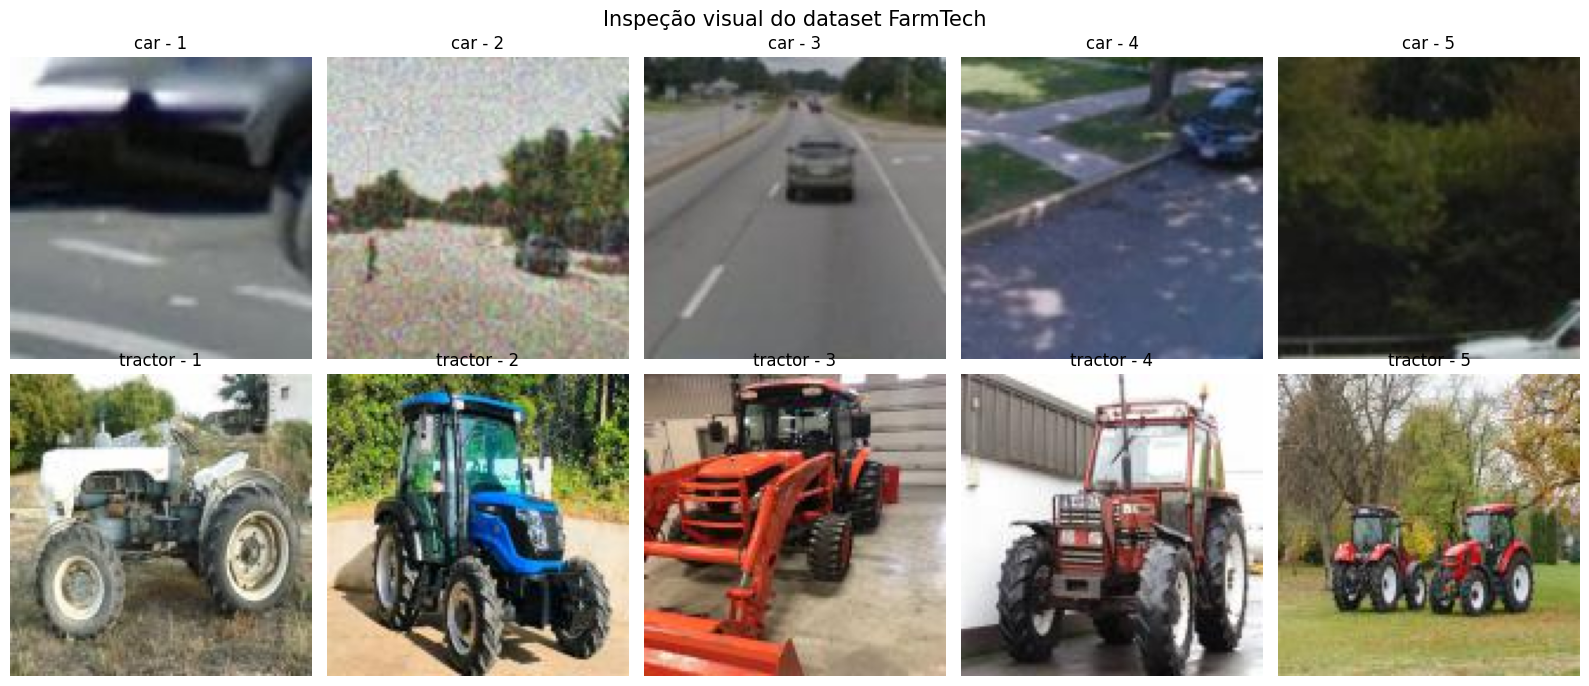

In [ ]:
import zipfile
import io
import matplotlib.pyplot as plt
from PIL import Image

arquivo_zip = arquivos_zip[0]

fig, axes = plt.subplots(2, 5, figsize=(16, 7))

with zipfile.ZipFile(arquivo_zip, "r") as zip_ref:

    for linha, classe in enumerate(["car", "tractor"]):

        amostras = selecionados[classe][:5]

        for coluna, item in enumerate(amostras):

            caminho_imagem = item["imagem"]

            dados = zip_ref.read(caminho_imagem)
            imagem = Image.open(io.BytesIO(dados)).convert("RGB")

            axes[linha, coluna].imshow(imagem)
            axes[linha, coluna].set_title(
                f"{classe} - {coluna + 1}"
            )
            axes[linha, coluna].axis("off")

plt.suptitle(
    "Inspeção visual do dataset FarmTech",
    fontsize=15
)

plt.tight_layout()
plt.show()

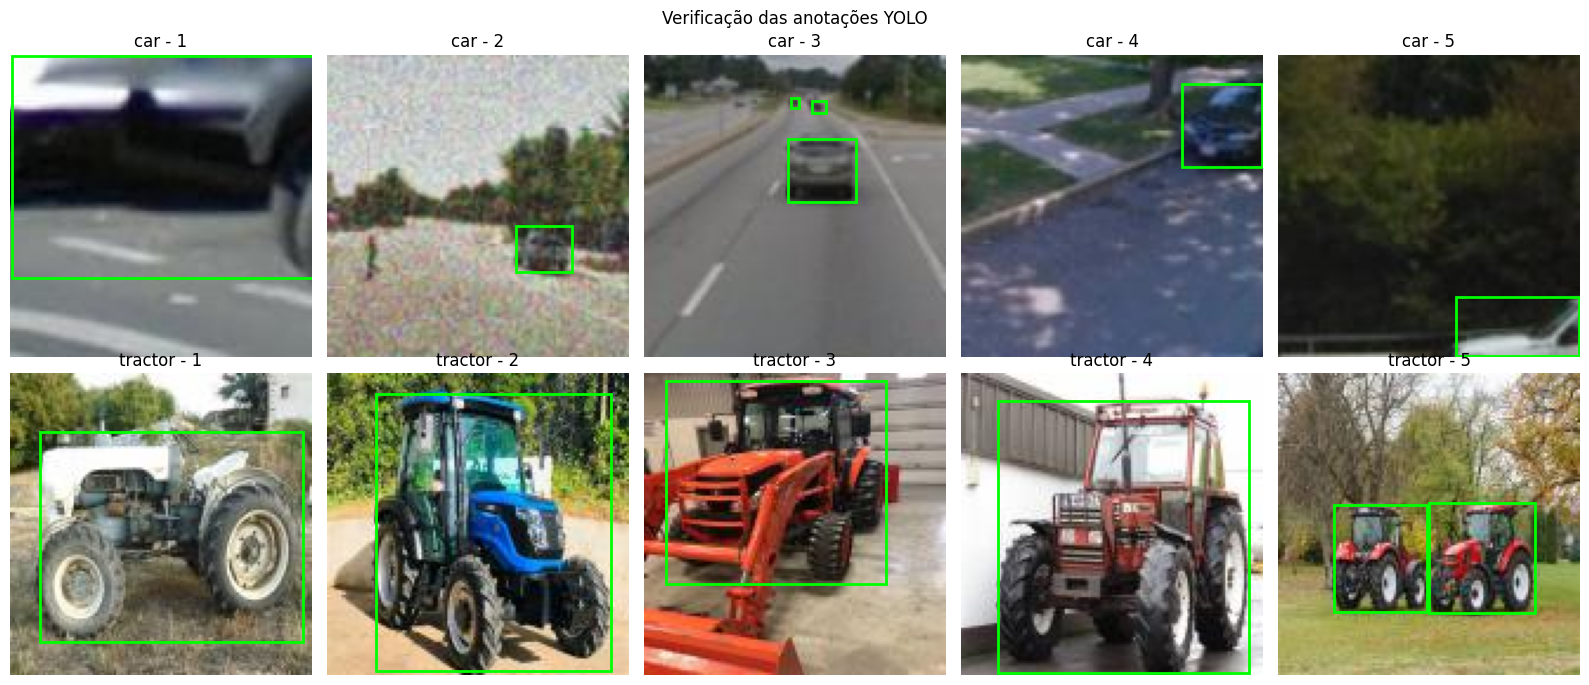

In [ ]:
import zipfile
import io
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

fig, axes = plt.subplots(2, 5, figsize=(16, 7))

with zipfile.ZipFile(arquivos_zip[0], "r") as zip_ref:

    for linha, classe in enumerate(["car", "tractor"]):

        for coluna, item in enumerate(selecionados[classe][:5]):

            caminho_imagem = item["imagem"]
            caminho_label = item["anotacao"]

            imagem = Image.open(
                io.BytesIO(zip_ref.read(caminho_imagem))
            ).convert("RGB")

            largura, altura = imagem.size
            ax = axes[linha, coluna]

            ax.imshow(imagem)

            conteudo = zip_ref.read(
                caminho_label
            ).decode("utf-8")

            for anotacao in conteudo.splitlines():

                partes = anotacao.split()

                if len(partes) != 5:
                    continue

                classe_id = int(partes[0])

                x, y, w, h = map(float, partes[1:])

                x1 = (x - w / 2) * largura
                y1 = (y - h / 2) * altura

                retangulo = patches.Rectangle(
                    (x1, y1),
                    w * largura,
                    h * altura,
                    linewidth=2,
                    edgecolor="lime",
                    facecolor="none"
                )

                ax.add_patch(retangulo)

            ax.set_title(f"{classe} - {coluna + 1}")
            ax.axis("off")

plt.suptitle("Verificação das anotações YOLO")
plt.tight_layout()
plt.show()

In [ ]:
import hashlib
import zipfile
from collections import defaultdict

grupos_hash = defaultdict(list)

with zipfile.ZipFile(arquivos_zip[0], "r") as zip_ref:

    for classe in ["car", "tractor"]:

        for item in selecionados[classe]:

            caminho = item["imagem"]
            dados = zip_ref.read(caminho)

            assinatura = hashlib.sha256(dados).hexdigest()

            grupos_hash[assinatura].append(
                (classe, caminho)
            )

duplicatas = {
    assinatura: arquivos
    for assinatura, arquivos in grupos_hash.items()
    if len(arquivos) > 1
}

print("VERIFICAÇÃO DE DUPLICATAS EXATAS")
print("=" * 45)
print("Total de imagens:", 80)
print("Conteúdos únicos:", len(grupos_hash))
print("Grupos duplicados:", len(duplicatas))

if not duplicatas:
    print("\nNenhuma duplicata exata encontrada.")
else:
    print("\nDuplicatas encontradas:")
    for arquivos in duplicatas.values():
        print(arquivos)

VERIFICAÇÃO DE DUPLICATAS EXATAS
Total de imagens: 80
Conteúdos únicos: 80
Grupos duplicados: 0

Nenhuma duplicata exata encontrada.


In [ ]:
import random

divisoes = {
    "train": [],
    "val": [],
    "test": []
}

for classe in ["car", "tractor"]:

    imagens = selecionados[classe].copy()

    random.Random(42).shuffle(imagens)

    divisoes["train"].extend(imagens[:32])
    divisoes["val"].extend(imagens[32:36])
    divisoes["test"].extend(imagens[36:40])

print("DIVISÃO DO DATASET FARMTECH")
print("=" * 45)

for divisao, imagens in divisoes.items():

    print(f"{divisao}: {len(imagens)} imagens")

print("\nTotal:", sum(len(v) for v in divisoes.values()))

assert len(divisoes["train"]) == 64
assert len(divisoes["val"]) == 8
assert len(divisoes["test"]) == 8

print("\nDivisão concluída com sucesso.")

DIVISÃO DO DATASET FARMTECH
train: 64 imagens
val: 8 imagens
test: 8 imagens

Total: 80

Divisão concluída com sucesso.


In [ ]:
from pathlib import Path
from collections import Counter
import zipfile
import yaml

DATASET_DIR = PROJECT_DIR / "dataset"

MAPA_CLASSES = {
    3: 0,   # car
    11: 1   # tractor
}

contagem = Counter()

with zipfile.ZipFile(arquivos_zip[0], "r") as zip_ref:

    for divisao, itens in divisoes.items():

        for item in itens:

            origem_imagem = item["imagem"]
            origem_label = item["anotacao"]

            destino_imagem = (
                DATASET_DIR / "images" / divisao /
                Path(origem_imagem).name
            )

            destino_label = (
                DATASET_DIR / "labels" / divisao /
                Path(origem_label).name
            )

            linhas_convertidas = []

            conteudo = zip_ref.read(
                origem_label
            ).decode("utf-8")

            for linha in conteudo.splitlines():

                partes = linha.strip().split()

                if len(partes) != 5:
                    raise ValueError(
                        f"Anotação inválida: {origem_label}"
                    )

                classe_original = int(partes[0])

                if classe_original not in MAPA_CLASSES:
                    raise ValueError(
                        f"Classe inesperada: {classe_original}"
                    )

                nova_classe = MAPA_CLASSES[classe_original]

                coordenadas = [float(v) for v in partes[1:]]

                if not all(0 <= v <= 1 for v in coordenadas):
                    raise ValueError(
                        f"Coordenadas inválidas: {origem_label}"
                    )

                linhas_convertidas.append(
                    " ".join(
                        [str(nova_classe)] + partes[1:]
                    )
                )

                contagem[(divisao, nova_classe)] += 1

            if not linhas_convertidas:
                raise ValueError(
                    f"Anotação vazia: {origem_label}"
                )

            destino_imagem.parent.mkdir(
                parents=True, exist_ok=True
            )

            destino_label.parent.mkdir(
                parents=True, exist_ok=True
            )

            destino_imagem.write_bytes(
                zip_ref.read(origem_imagem)
            )

            destino_label.write_text(
                "\n".join(linhas_convertidas) + "\n",
                encoding="utf-8"
            )

configuracao = {
    "path": str(DATASET_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 2,
    "names": ["car", "tractor"]
}

with open(DATASET_DIR / "data.yaml", "w") as arquivo:
    yaml.safe_dump(
        configuracao,
        arquivo,
        sort_keys=False,
        allow_unicode=True
    )

print("DATASET FINAL FARMTECH")
print("=" * 45)

for divisao in ["train", "val", "test"]:

    imagens = list(
        (DATASET_DIR / "images" / divisao).glob("*")
    )

    labels = list(
        (DATASET_DIR / "labels" / divisao).glob("*.txt")
    )

    print(f"\n{divisao}")
    print("Imagens:", len(imagens))
    print("Labels:", len(labels))
    print("Anotações car:", contagem[(divisao, 0)])
    print("Anotações tractor:", contagem[(divisao, 1)])

print("\nArquivo data.yaml criado.")
print("Caminho:", DATASET_DIR / "data.yaml")

DATASET FINAL FARMTECH

train
Imagens: 64
Labels: 64
Anotações car: 71
Anotações tractor: 35

val
Imagens: 8
Labels: 8
Anotações car: 9
Anotações tractor: 6

test
Imagens: 8
Labels: 8
Anotações car: 9
Anotações tractor: 4

Arquivo data.yaml criado.
Caminho: /content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/data.yaml


In [ ]:
from pathlib import Path
from collections import Counter
import yaml

DATASET_DIR = PROJECT_DIR / "dataset"

with open(DATASET_DIR / "data.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)

assert config["nc"] == 2
assert config["names"] == ["car", "tractor"]

print("VALIDAÇÃO FINAL DO DATASET")
print("=" * 45)

total_imagens = 0
total_anotacoes = Counter()

for divisao in ["train", "val", "test"]:

    pasta_imagens = DATASET_DIR / "images" / divisao
    pasta_labels = DATASET_DIR / "labels" / divisao

    imagens = sorted(
        p for p in pasta_imagens.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    )

    labels = sorted(pasta_labels.glob("*.txt"))

    nomes_imagens = {p.stem for p in imagens}
    nomes_labels = {p.stem for p in labels}

    assert nomes_imagens == nomes_labels, (
        f"Imagens e labels não correspondem em {divisao}"
    )

    contagem = Counter()

    for label in labels:
        for linha in label.read_text().splitlines():

            partes = linha.split()

            assert len(partes) == 5, f"Formato inválido: {label}"

            classe = int(partes[0])
            valores = [float(v) for v in partes[1:]]

            assert classe in [0, 1], f"Classe inválida: {label}"
            assert all(0 <= v <= 1 for v in valores)

            x, y, w, h = valores

            assert w > 0 and h > 0
            assert w / 2 <= x <= 1 - w / 2
            assert h / 2 <= y <= 1 - h / 2

            contagem[classe] += 1

    total_imagens += len(imagens)
    total_anotacoes.update(contagem)

    print(f"\n{divisao.upper()}")
    print("Imagens:", len(imagens))
    print("Labels:", len(labels))
    print("Carros anotados:", contagem[0])
    print("Tratores anotados:", contagem[1])

assert total_imagens == 80

print("\n" + "=" * 45)
print("TOTAL DE IMAGENS:", total_imagens)
print("TOTAL DE ANOTAÇÕES:", sum(total_anotacoes.values()))
print("DATASET VALIDADO COM SUCESSO!")

VALIDAÇÃO FINAL DO DATASET

TRAIN
Imagens: 64
Labels: 64
Carros anotados: 71
Tratores anotados: 35

VAL
Imagens: 8
Labels: 8
Carros anotados: 9
Tratores anotados: 6

TEST
Imagens: 8
Labels: 8
Carros anotados: 9
Tratores anotados: 4

TOTAL DE IMAGENS: 80
TOTAL DE ANOTAÇÕES: 134
DATASET VALIDADO COM SUCESSO!


In [ ]:
import torch

print("VERIFICAÇÃO DA GPU")
print("=" * 40)
print("PyTorch:", torch.__version__)
print("CUDA disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU detectada:", torch.cuda.get_device_name(0))
    print("Ambiente pronto para treinamento YOLO!")
else:
    print("GPU não detectada. Verifique o ambiente.")

VERIFICAÇÃO DA GPU
PyTorch: 2.11.0+cu130
CUDA disponível: True
GPU detectada: Tesla T4
Ambiente pronto para treinamento YOLO!


In [ ]:
%pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 47.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 11.0 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO
import ultralytics

print("VERIFICAÇÃO DO ULTRALYTICS")
print("=" * 40)
print("Versão:", ultralytics.__version__)
print("Biblioteca YOLO importada com sucesso!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
VERIFICAÇÃO DO ULTRALYTICS
Versão: 8.4.175
Biblioteca YOLO importada com sucesso!


In [ ]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/FarmTech_Vision_Fase6"
)

print("VERIFICAÇÃO DOS ARQUIVOS DO PROJETO")
print("=" * 45)

print("Pasta do projeto:", PROJECT_DIR.exists())

if PROJECT_DIR.exists():
    arquivos_yaml = list(PROJECT_DIR.rglob("data.yaml"))

    print("\nArquivos data.yaml encontrados:")

    if arquivos_yaml:
        for arquivo in arquivos_yaml:
            print(arquivo)
    else:
        print("Nenhum data.yaml encontrado.")

    print("\nPastas do projeto:")
    for pasta in sorted(PROJECT_DIR.iterdir()):
        print(pasta.name)
else:
    print("Pasta do projeto não encontrada no Drive.")

Mounted at /content/drive
VERIFICAÇÃO DOS ARQUIVOS DO PROJETO
Pasta do projeto: True

Arquivos data.yaml encontrados:
/content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/data.yaml

Pastas do projeto:
dataset
docs
downloads
results


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/data.yaml'

In [ ]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive", force_remount=True)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/FarmTech_Vision_Fase6"
)

DATASET_DIR = PROJECT_DIR / "dataset"
yaml_path = DATASET_DIR / "data.yaml"

print("VERIFICAÇÃO DO PROJETO")
print("=" * 45)

print("Projeto existe:", PROJECT_DIR.exists())
print("Dataset existe:", DATASET_DIR.exists())
print("data.yaml existe:", yaml_path.exists())

if DATASET_DIR.exists():
    print("\nArquivos dentro do dataset:")
    for item in sorted(DATASET_DIR.iterdir()):
        print("-", item.name)

Mounted at /content/drive
VERIFICAÇÃO DO PROJETO
Projeto existe: True
Dataset existe: True
data.yaml existe: True

Arquivos dentro do dataset:
- data.yaml
- images
- labels


In [ ]:
import yaml

yaml_path = DATASET_DIR / "data.yaml"

with open(yaml_path, "r", encoding="utf-8") as arquivo:
    config = yaml.safe_load(arquivo)

print("CONFIGURAÇÃO DO DATASET YOLO")
print("=" * 45)

print(config)

print("\nCLASSES CONFIGURADAS:")
print(config.get("names"))

print("\nVERIFICAÇÃO DAS PASTAS:")

for divisao in ["train", "val", "test"]:
    pasta_imagens = DATASET_DIR / "images" / divisao
    pasta_labels = DATASET_DIR / "labels" / divisao

    imagens = [
        p for p in pasta_imagens.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ] if pasta_imagens.exists() else []

    labels = list(pasta_labels.glob("*.txt")) if pasta_labels.exists() else []

    print(f"\n{divisao.upper()}")
    print("Imagens:", len(imagens))
    print("Labels:", len(labels))

CONFIGURAÇÃO DO DATASET YOLO
{'path': '/content/drive/MyDrive/FarmTech_Vision_Fase6/dataset', 'train': 'images/train', 'val': 'images/val', 'test': 'images/test', 'nc': 2, 'names': ['car', 'tractor']}

CLASSES CONFIGURADAS:
['car', 'tractor']

VERIFICAÇÃO DAS PASTAS:

TRAIN
Imagens: 64
Labels: 64

VAL
Imagens: 8
Labels: 8

TEST
Imagens: 8
Labels: 8


In [ ]:
from ultralytics import YOLO
import torch

print("INICIANDO TREINAMENTO FARMTECH")
print("=" * 45)

# Confirmar GPU
device = 0 if torch.cuda.is_available() else "cpu"

print("Dispositivo:", device)
print("Dataset:", yaml_path)

# Carregar modelo pré-treinado pequeno
modelo = YOLO("yolov8n.pt")

# Treinar
resultados = modelo.train(
    data=str(yaml_path),
    epochs=30,
    imgsz=640,
    batch=8,
    device=device,
    workers=2,
    seed=42,
    project=str(PROJECT_DIR / "results"),
    name="farmtech_yolo_v1",
    exist_ok=True,
    plots=True
)

print("\nTREINAMENTO FINALIZADO!")

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
%pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 9.5 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO
import ultralytics
import torch

print("VERIFICAÇÃO DO AMBIENTE")
print("=" * 40)

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nBibliotecas verificadas com sucesso!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
VERIFICAÇÃO DO AMBIENTE
Ultralytics: 8.4.175
PyTorch: 2.11.0+cu130
CUDA disponível: True
GPU: Tesla T4

Bibliotecas verificadas com sucesso!


In [ ]:
from pathlib import Path
from ultralytics import YOLO
import torch

PROJECT_DIR = Path(
    "/content/drive/MyDrive/FarmTech_Vision_Fase6"
)

yaml_path = PROJECT_DIR / "dataset" / "data.yaml"

assert yaml_path.exists(), "Arquivo data.yaml não encontrado!"

print("INICIANDO TREINAMENTO FARMTECH")
print("=" * 45)
print("Dataset:", yaml_path)
print("GPU disponível:", torch.cuda.is_available())

modelo = YOLO("yolov8n.pt")

resultados = modelo.train(
    data=str(yaml_path),
    epochs=30,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    seed=42,
    project=str(PROJECT_DIR / "results"),
    name="farmtech_yolo_v1",
    exist_ok=True,
    plots=True
)

print("\nTREINAMENTO FINALIZADO COM SUCESSO!")

INICIANDO TREINAMENTO FARMTECH
Dataset: /content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/data.yaml
GPU disponível: True
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=

In [ ]:
from pathlib import Path
from ultralytics import YOLO

PROJECT_DIR = Path(
    "/content/drive/MyDrive/FarmTech_Vision_Fase6"
)

modelo_path = (
    PROJECT_DIR
    / "results"
    / "farmtech_yolo_v1"
    / "weights"
    / "best.pt"
)

yaml_path = PROJECT_DIR / "dataset" / "data.yaml"

assert modelo_path.exists(), "Modelo best.pt não encontrado!"
assert yaml_path.exists(), "Arquivo data.yaml não encontrado!"

modelo_teste = YOLO(str(modelo_path))

metricas_teste = modelo_teste.val(
    data=str(yaml_path),
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    project=str(PROJECT_DIR / "results"),
    name="avaliacao_teste",
    exist_ok=True,
    plots=True
)

print("\nRESULTADOS DO TESTE FINAL")
print("=" * 45)
print(f"Precisão: {metricas_teste.box.mp:.4f}")
print(f"Recall: {metricas_teste.box.mr:.4f}")
print(f"mAP@50: {metricas_teste.box.map50:.4f}")
print(f"mAP@50-95: {metricas_teste.box.map:.4f}")
print("\nAvaliação concluída!")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.2 ms, read: 0.0±0.0 MB/s, size: 4.3 KB)
val: Scanning /content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/labels/test... 8 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8/8 1.7it/s 4.6s
val: New cache created: /content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 5.8it/s 0.2s
                   all          8         13      0.841      0.655      0.742      0.293
                   car          4          9          1      0.311       0.59       0.27
               tractor          4          4      0.681          1      0.895      0.317
Speed: 0.4ms preprocess, 7.9ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /content/drive/MyDr

IMAGENS DE TESTE: 8

0: 640x640 1 tractor, 6.8ms
1: 640x640 (no detections), 6.8ms
2: 640x640 1 car, 6.8ms
3: 640x640 2 cars, 6.8ms
4: 640x640 2 tractors, 6.8ms
5: 640x640 4 tractors, 6.8ms
6: 640x640 3 tractors, 6.8ms
7: 640x640 4 tractors, 6.8ms
Speed: 2.0ms preprocess, 6.8ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/drive/MyDrive/FarmTech_Vision_Fase6/results/predicoes_teste


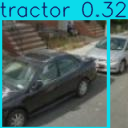

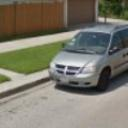

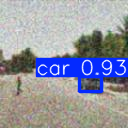

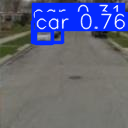

In [ ]:
from pathlib import Path
from ultralytics import YOLO
from IPython.display import display
from PIL import Image

PROJECT_DIR = Path(
    "/content/drive/MyDrive/FarmTech_Vision_Fase6"
)

modelo_path = (
    PROJECT_DIR / "results"
    / "farmtech_yolo_v1"
    / "weights" / "best.pt"
)

pasta_teste = PROJECT_DIR / "dataset" / "images" / "test"

modelo = YOLO(str(modelo_path))

imagens = sorted([
    p for p in pasta_teste.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

print("IMAGENS DE TESTE:", len(imagens))

resultados = modelo.predict(
    source=[str(p) for p in imagens],
    conf=0.25,
    imgsz=640,
    device=0,
    save=True,
    project=str(PROJECT_DIR / "results"),
    name="predicoes_teste",
    exist_ok=True
)

for resultado in resultados[:4]:
    imagem_anotada = Image.fromarray(
        resultado.plot()[..., ::-1]
    )
    display(imagem_anotada)

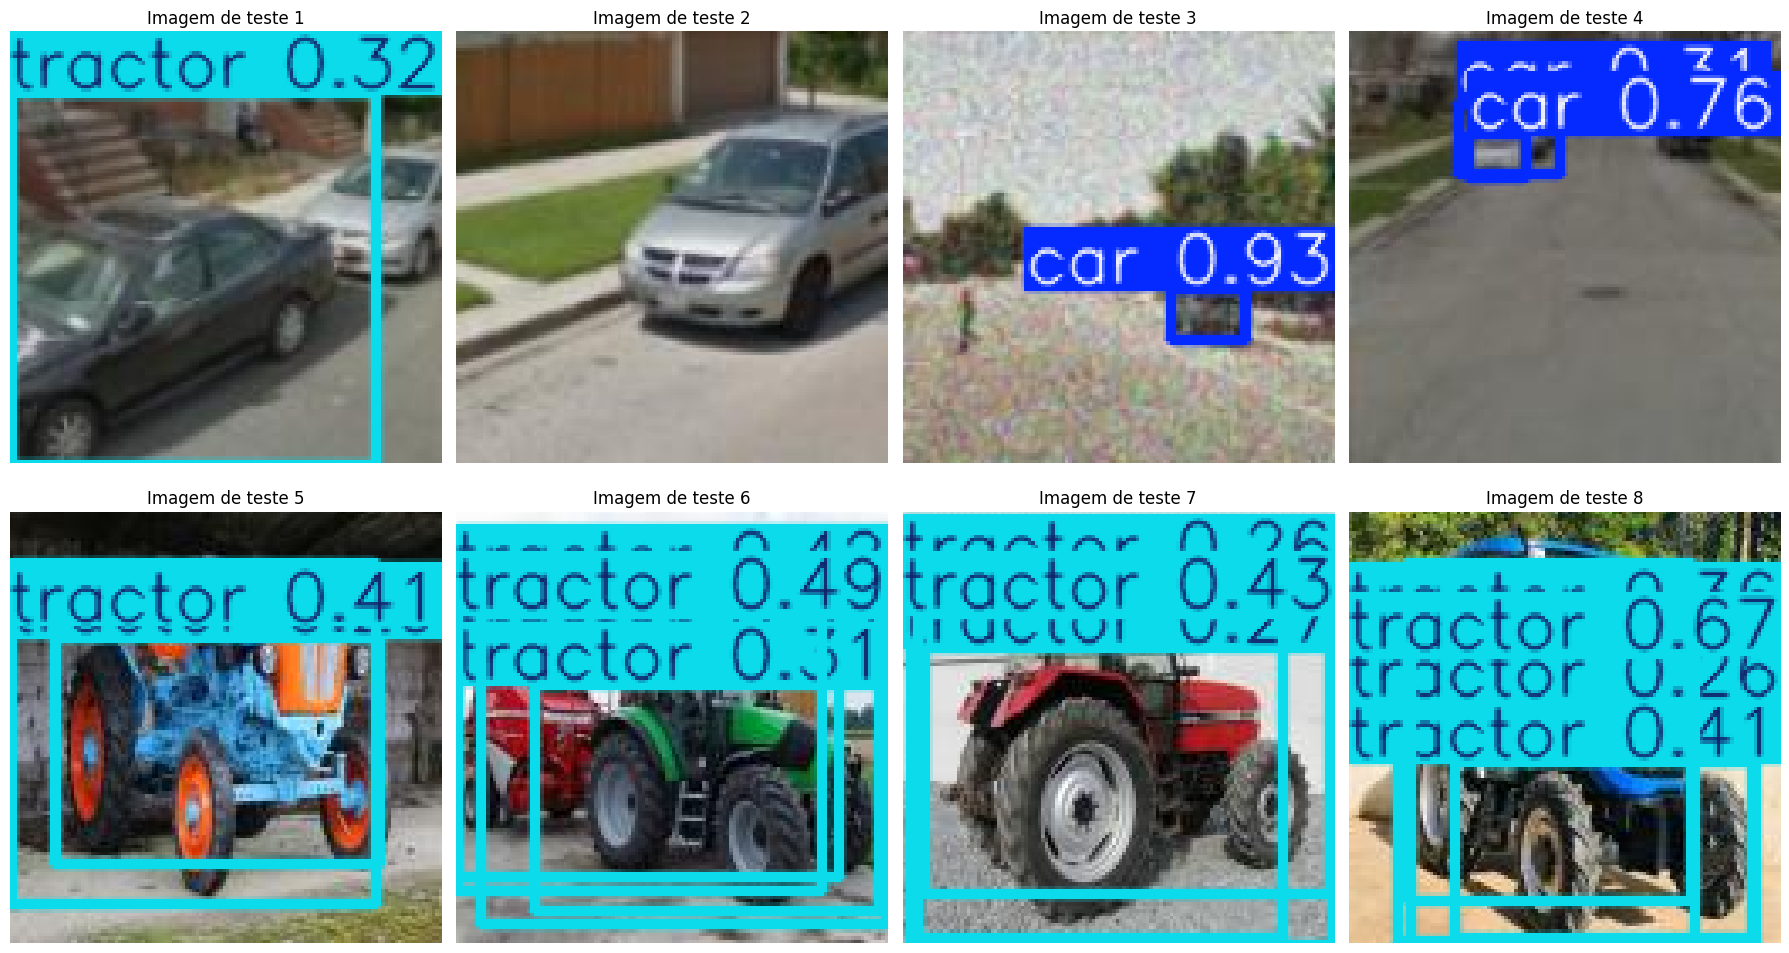

Figura salva em: /content/drive/MyDrive/FarmTech_Vision_Fase6/results/predicoes_teste/comparacao_deteccoes.png


In [ ]:
import matplotlib.pyplot as plt
import cv2

fig, axes = plt.subplots(2, 4, figsize=(18, 10))

for i, resultado in enumerate(resultados):
    imagem = resultado.plot()
    imagem = cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)

    ax = axes[i // 4, i % 4]
    ax.imshow(imagem)
    ax.set_title(f"Imagem de teste {i + 1}")
    ax.axis("off")

plt.tight_layout()

caminho_figura = (
    PROJECT_DIR / "results" / "predicoes_teste"
    / "comparacao_deteccoes.png"
)

plt.savefig(caminho_figura, dpi=150, bbox_inches="tight")
plt.show()

print("Figura salva em:", caminho_figura)

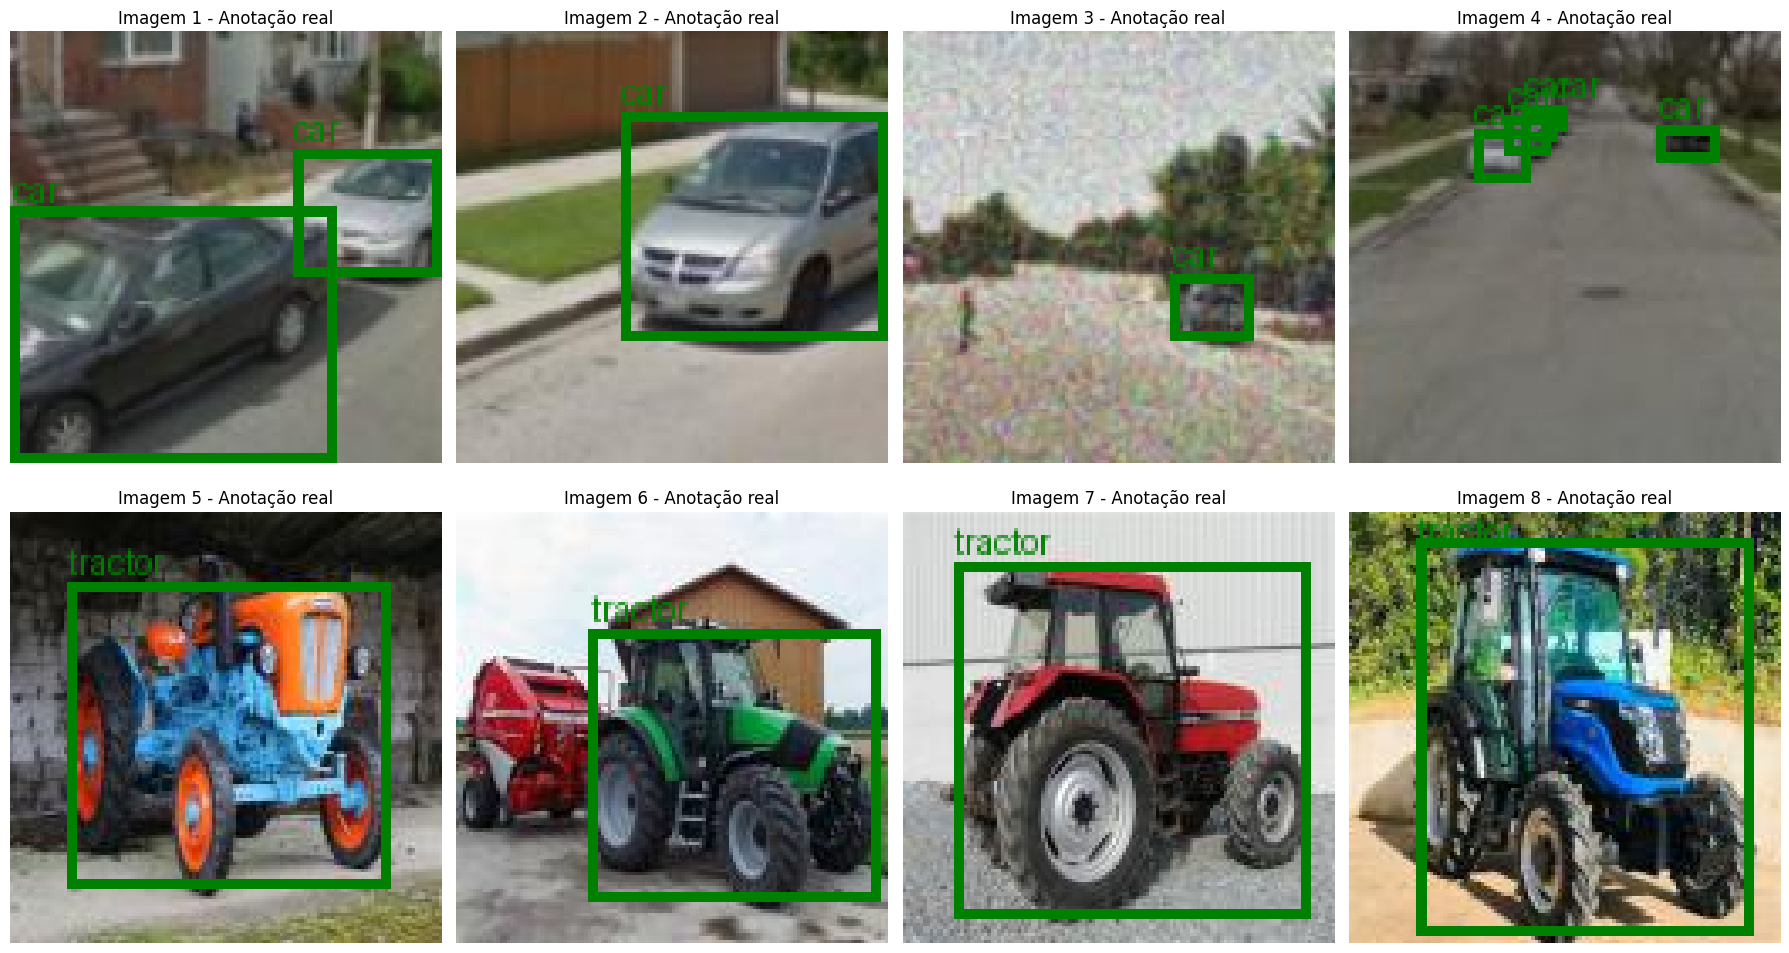

Anotações reais salvas em: /content/drive/MyDrive/FarmTech_Vision_Fase6/results/predicoes_teste/anotacoes_reais.png


In [ ]:
from pathlib import Path
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

dataset_dir = PROJECT_DIR / "dataset"

fig, axes = plt.subplots(2, 4, figsize=(18, 10))

for i, resultado in enumerate(resultados):
    caminho = Path(resultado.path)
    imagem = Image.open(caminho).convert("RGB")

    largura, altura = imagem.size
    desenho = ImageDraw.Draw(imagem)

    label_path = (
        dataset_dir / "labels" / "test"
        / f"{caminho.stem}.txt"
    )

    if label_path.exists():
        for linha in label_path.read_text().splitlines():
            valores = linha.split()

            if len(valores) != 5:
                continue

            classe, xc, yc, w, h = map(float, valores)

            x1 = (xc - w / 2) * largura
            y1 = (yc - h / 2) * altura
            x2 = (xc + w / 2) * largura
            y2 = (yc + h / 2) * altura

            desenho.rectangle(
                [x1, y1, x2, y2],
                outline="green",
                width=3
            )

            nome = modelo.names[int(classe)]
            desenho.text(
                (x1, max(0, y1 - 12)),
                nome,
                fill="green"
            )

    ax = axes[i // 4, i % 4]
    ax.imshow(imagem)
    ax.set_title(f"Imagem {i + 1} - Anotação real")
    ax.axis("off")

plt.tight_layout()

caminho_saida = (
    PROJECT_DIR / "results"
    / "predicoes_teste"
    / "anotacoes_reais.png"
)

plt.savefig(caminho_saida, dpi=150, bbox_inches="tight")
plt.show()

print("Anotações reais salvas em:", caminho_saida)

## 6. Conferir a estrutura do dataset

Antes de treinar, a estrutura deve conter imagens e rótulos correspondentes. Para detecção YOLO, cada arquivo de rótulo `.txt` deve conter uma linha por objeto, no formato:

`id_da_classe x_centro y_centro largura altura`

As coordenadas devem estar normalizadas entre 0 e 1. A classe `0` será `trator` e a classe `1` será `carro`.

A anotação será feita com o Make Sense AI e exportada em formato compatível com YOLO. Não avance para o treinamento enquanto as imagens e os rótulos não estiverem revisados.

In [ ]:
SPLITS = ['train', 'val', 'test']

for split in SPLITS:
    images_dir = DATASET_DIR / 'images' / split
    labels_dir = DATASET_DIR / 'labels' / split
    images = []
    if images_dir.exists():
        images = [p for p in images_dir.iterdir()
                  if p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.webp'}]
    labels = list(labels_dir.glob('*.txt')) if labels_dir.exists() else []
    print(f'{split}: {len(images)} imagens | {len(labels)} arquivos de rótulo')

## 7. Criar a configuração do dataset para YOLO

Esta célula gera um arquivo `data.yaml` apontando para as pastas do Drive. Confira o caminho e a estrutura antes de treinar.

In [ ]:
import yaml

data_yaml = {
    'path': str(DATASET_DIR),
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'names': {0: 'trator', 1: 'carro'}
}

yaml_path = PROJECT_DIR / 'data.yaml'
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
with open(yaml_path, 'w', encoding='utf-8') as f:
    yaml.safe_dump(data_yaml, f, sort_keys=False, allow_unicode=True)

print(yaml_path.read_text(encoding='utf-8'))

## 8. Treinar o YOLO personalizado — 30 épocas

**Execute somente depois de completar e conferir o dataset.** A arquitetura inicial será YOLOv8n por ser uma variante leve para um experimento introdutório. Registre o tempo e preserve os resultados gerados.

In [ ]:
from ultralytics import YOLO
import time

DATA_YAML = str(PROJECT_DIR / 'data.yaml')
model_30 = YOLO('yolov8n.pt')

start_30 = time.perf_counter()
results_30 = model_30.train(
    data=DATA_YAML,
    epochs=30,
    imgsz=640,
    seed=42,
    project=str(RESULTS_DIR / 'yolo_custom'),
    name='treino_30_epocas',
    exist_ok=True
)
time_30 = time.perf_counter() - start_30

print(f'Tempo de treinamento (30 épocas): {time_30:.2f} segundos')

## 9. Treinar o YOLO personalizado — 60 épocas

Para tornar a comparação mais útil, manteremos a mesma arquitetura, dataset, tamanho de imagem e semente, alterando o número de épocas. Os treinamentos podem variar devido ao ambiente computacional; os tempos devem ser medidos no ambiente em que forem executados.

In [25]:
from ultralytics import YOLO
from pathlib import Path
import time

PROJECT_DIR = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6")
DATA_YAML = str(PROJECT_DIR / "data.yaml")
RESULTS_DIR = PROJECT_DIR / "results"

modelo_60 = YOLO("yolov8n.pt")

inicio = time.perf_counter()

resultado_60 = modelo_60.train(
    data=DATA_YAML,
    epochs=60,
    imgsz=640,
    seed=42,
    project=str(RESULTS_DIR / "yolo_custom"),
    name="treino_60_epocas",
    exist_ok=True,
    patience=60
)

tempo_60 = time.perf_counter() - inicio

print("Treinamento de 60 épocas finalizado!")
print("Tempo total:", round(tempo_60, 2), "segundos")

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/FarmTech_Vision_Fase6/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=treino_60_epocas, nbs=64, nms=None, 

In [9]:
from pathlib import Path

base = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6")

caminhos = {
    "YOLO 30 épocas": base / "results/yolo_custom/treino_30_epocas/weights/best.pt",
    "YOLO 60 épocas": base / "results/yolo_custom/treino_60_epocas/weights/best.pt",
}

for nome, caminho in caminhos.items():
    print(f"{nome}: {'ENCONTRADO' if caminho.exists() else 'NÃO ENCONTRADO'}")

YOLO 30 épocas: NÃO ENCONTRADO
YOLO 60 épocas: NÃO ENCONTRADO


In [10]:
from pathlib import Path

base = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6")

print("DIAGNÓSTICO FINAL FARMTECH")
print("=" * 45)

for padrao in ["best.pt", "*.keras", "*.h5", "results.csv"]:
    arquivos = sorted(base.rglob(padrao))
    print(f"\n{padrao}: {len(arquivos)} encontrado(s)")

    for arquivo in arquivos:
        print(" -", arquivo.relative_to(base))

print("\nDiagnóstico concluído.")

DIAGNÓSTICO FINAL FARMTECH

best.pt: 1 encontrado(s)
 - results/farmtech_yolo_v1/weights/best.pt

*.keras: 0 encontrado(s)

*.h5: 0 encontrado(s)

results.csv: 1 encontrado(s)
 - results/farmtech_yolo_v1/results.csv

Diagnóstico concluído.


In [11]:
from pathlib import Path
import torch

PROJECT_DIR = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6")
RESULTS_DIR = PROJECT_DIR / "results"
DATA_YAML = str(PROJECT_DIR / "data.yaml")

print("Projeto:", PROJECT_DIR.exists())
print("Dataset YAML:", Path(DATA_YAML).exists())
print("GPU disponível:", torch.cuda.is_available())
print("Resultados:", RESULTS_DIR.exists())

Projeto: True
Dataset YAML: False
GPU disponível: True
Resultados: True


In [12]:
import yaml

config = {
    "path": str(PROJECT_DIR / "dataset"),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 2,
    "names": ["car", "tractor"]
}

with open(DATA_YAML, "w", encoding="utf-8") as arquivo:
    yaml.safe_dump(config, arquivo, sort_keys=False)

print("Arquivo data.yaml criado:", Path(DATA_YAML).exists())
print("Local:", DATA_YAML)

Arquivo data.yaml criado: True
Local: /content/drive/MyDrive/FarmTech_Vision_Fase6/data.yaml


In [15]:
from ultralytics import YOLO
from pathlib import Path

modelo_path = PROJECT_DIR / "results/farmtech_yolo_v1/weights/best.pt"

modelo = YOLO(str(modelo_path))

metricas = modelo.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    project=str(PROJECT_DIR / "results"),
    name="avaliacao_final",
    exist_ok=True
)

print("\nRESULTADOS DA AVALIAÇÃO")
print("Precisão:", round(metricas.box.mp, 4))
print("Recall:", round(metricas.box.mr, 4))
print("mAP50:", round(metricas.box.map50, 4))
print("mAP50-95:", round(metricas.box.map, 4))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.2 ms, read: 0.0±0.0 MB/s, size: 4.3 KB)
val: Scanning /content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/labels/test.cache... 8 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8/8 1.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 3.5s/it 3.5s
                   all          8         13      0.841      0.655      0.742      0.293
                   car          4          9          1      0.311       0.59       0.27
  

In [14]:
%pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 78.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 10.9 MB/s eta 0:00:00


In [22]:
from pathlib import Path
import pandas as pd

base = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6")
csv = base / "results/farmtech_yolo_v1/results.csv"

if csv.exists():
    df = pd.read_csv(csv)
    df.columns = df.columns.str.strip()

    print("Épocas registradas:", len(df))
    print("Última época:", df["epoch"].iloc[-1])
    print("Melhor mAP50:", round(df["metrics/mAP50(B)"].max(), 4))
else:
    print("Arquivo de treinamento não encontrado.")

Épocas registradas: 30
Última época: 30
Melhor mAP50: 0.6068


In [24]:
from pathlib import Path

base = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6")

print("MODELOS YOLO ENCONTRADOS:")

for arquivo in base.rglob("best.pt"):
    print(arquivo.relative_to(base))

MODELOS YOLO ENCONTRADOS:
results/farmtech_yolo_v1/weights/best.pt


## 10. Validação e teste do modelo

Depois dos treinamentos, avalie os melhores pesos de cada execução no conjunto de teste. Guarde as métricas retornadas pelo modelo e compare os resultados sem presumir que 60 épocas será necessariamente melhor.

In [ ]:
best_30 = RESULTS_DIR / 'yolo_custom' / 'treino_30_epocas' / 'weights' / 'best.pt'
best_60 = RESULTS_DIR / 'yolo_custom' / 'treino_60_epocas' / 'weights' / 'best.pt'

for label, weights in [('YOLO 30 épocas', best_30), ('YOLO 60 épocas', best_60)]:
    if weights.exists():
        test_model = YOLO(str(weights))
        metrics = test_model.val(data=DATA_YAML, split='test')
        print(f'\n{label}')
        print(metrics.results_dict)
    else:
        print(f'Pesos ainda não encontrados para {label}: {weights}')

In [26]:
from pathlib import Path

base = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6")

caminhos = {
    "Modelo original": base / "results/farmtech_yolo_v1/weights/best.pt",
    "YOLO 30 épocas": base / "results/yolo_custom/treino_30_epocas/weights/best.pt",
    "YOLO 60 épocas": base / "results/yolo_custom/treino_60_epocas/weights/best.pt"
}

for nome, caminho in caminhos.items():
    print(f"{nome}: {'ENCONTRADO' if caminho.is_file() else 'NÃO ENCONTRADO'}")
    print(caminho)
    print("-" * 50)

Modelo original: ENCONTRADO
/content/drive/MyDrive/FarmTech_Vision_Fase6/results/farmtech_yolo_v1/weights/best.pt
--------------------------------------------------
YOLO 30 épocas: NÃO ENCONTRADO
/content/drive/MyDrive/FarmTech_Vision_Fase6/results/yolo_custom/treino_30_epocas/weights/best.pt
--------------------------------------------------
YOLO 60 épocas: ENCONTRADO
/content/drive/MyDrive/FarmTech_Vision_Fase6/results/yolo_custom/treino_60_epocas/weights/best.pt
--------------------------------------------------


In [27]:
from pathlib import Path

pastas = [
    Path("/content/drive/MyDrive/FarmTech_Vision_Fase6"),
    Path("/content/runs"),
    Path("/content/results")
]

for pasta in pastas:
    print(f"\nVERIFICANDO: {pasta}")

    if pasta.exists():
        arquivos = list(pasta.rglob("best.pt"))

        if arquivos:
            for arquivo in arquivos:
                print("ENCONTRADO:", arquivo)
        else:
            print("Nenhum modelo encontrado.")
    else:
        print("Pasta não existe.")


VERIFICANDO: /content/drive/MyDrive/FarmTech_Vision_Fase6
ENCONTRADO: /content/drive/MyDrive/FarmTech_Vision_Fase6/results/yolo_custom/treino_60_epocas/weights/best.pt
ENCONTRADO: /content/drive/MyDrive/FarmTech_Vision_Fase6/results/farmtech_yolo_v1/weights/best.pt

VERIFICANDO: /content/runs
Pasta não existe.

VERIFICANDO: /content/results
Pasta não existe.


In [28]:
from pathlib import Path

base = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6")

for arquivo in base.rglob("results.csv"):
    print("HISTÓRICO ENCONTRADO:", arquivo)

for pasta in base.rglob("train*"):
    if pasta.is_dir() and "yolo" in str(pasta).lower():
        print("PASTA DE TREINAMENTO:", pasta)

HISTÓRICO ENCONTRADO: /content/drive/MyDrive/FarmTech_Vision_Fase6/results/farmtech_yolo_v1/results.csv
HISTÓRICO ENCONTRADO: /content/drive/MyDrive/FarmTech_Vision_Fase6/results/yolo_custom/treino_60_epocas/results.csv


In [29]:
from pathlib import Path
import pandas as pd

base = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6")

historicos = {
    "Modelo original": base / "results/farmtech_yolo_v1/results.csv",
    "YOLO 60 épocas": base / "results/yolo_custom/treino_60_epocas/results.csv"
}

for nome, arquivo in historicos.items():
    print(f"\n{'=' * 45}")
    print(nome)

    if arquivo.exists():
        df = pd.read_csv(arquivo)
        df.columns = df.columns.str.strip()

        print("Épocas registradas:", len(df))
        print("Colunas disponíveis:", df.columns.tolist())

        if "metrics/mAP50(B)" in df.columns:
            print(
                "Melhor mAP50 de validação:",
                round(df["metrics/mAP50(B)"].max(), 4)
            )
    else:
        print("Histórico não encontrado.")


Modelo original
Épocas registradas: 30
Colunas disponíveis: ['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']
Melhor mAP50 de validação: 0.6068

YOLO 60 épocas
Épocas registradas: 60
Colunas disponíveis: ['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']
Melhor mAP50 de validação: 0.7048


In [30]:
from pathlib import Path
import pandas as pd

base = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6")

historicos = {
    "YOLO 30 épocas": base / "results/farmtech_yolo_v1/results.csv",
    "YOLO 60 épocas": base / "results/yolo_custom/treino_60_epocas/results.csv"
}

comparacao = []

for nome, arquivo in historicos.items():
    df = pd.read_csv(arquivo)
    df.columns = df.columns.str.strip()

    melhor = df.loc[df["metrics/mAP50(B)"].idxmax()]

    comparacao.append({
        "Modelo": nome,
        "Época do melhor mAP50": int(melhor["epoch"]),
        "Precisão": round(melhor["metrics/precision(B)"], 4),
        "Recall": round(melhor["metrics/recall(B)"], 4),
        "mAP50": round(melhor["metrics/mAP50(B)"], 4),
        "mAP50-95": round(melhor["metrics/mAP50-95(B)"], 4)
    })

resultado = pd.DataFrame(comparacao)

display(resultado)

,Modelo,Época do melhor mAP50,Precisão,Recall,mAP50,mAP50-95
0,YOLO 30 épocas,28,0.4872,0.6999,0.6068,0.3678
1,YOLO 60 épocas,52,0.9100,0.5207,0.7048,0.3079


In [31]:
from pathlib import Path
from ultralytics import YOLO

base = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6")

modelos = {
    "YOLO 30 épocas": base / "results/farmtech_yolo_v1/weights/best.pt",
    "YOLO 60 épocas": base / "results/yolo_custom/treino_60_epocas/weights/best.pt"
}

for nome, caminho in modelos.items():

    print(f"\nAVALIANDO: {nome}")

    if not caminho.exists():
        print("Modelo não encontrado:", caminho)
        continue

    modelo = YOLO(str(caminho))

    metricas = modelo.val(
        data=str(DATA_YAML),
        split="test",
        imgsz=640,
        plots=True,
        project=str(base / "results/avaliacao_final"),
        name=nome.replace(" ", "_"),
        exist_ok=True
    )

    print("Precisão:", round(metricas.box.mp, 4))
    print("Recall:", round(metricas.box.mr, 4))
    print("mAP50:", round(metricas.box.map50, 4))
    print("mAP50-95:", round(metricas.box.map, 4))


AVALIANDO: YOLO 30 épocas
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 1.5±1.7 ms, read: 4.1±1.8 MB/s, size: 4.1 KB)
val: Scanning /content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/labels/test.cache... 8 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8/8 1.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 4.9it/s 0.2s
                   all          8         13      0.841      0.655      0.742      0.293
                   car          4          9          1      0.311       0.59       0.27
               tractor          4          4      0.681          1      0.895      0.317
Speed: 0.4ms preprocess, 7.7ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to /content/drive/MyDrive/FarmTech_Vision_Fase6/results/avaliacao_final/YOLO_30_épo

## 11. Evidências visuais

Selecione imagens que não participaram do treino e registre as previsões. Inclua exemplos de acertos e, se existirem, erros relevantes. Não selecione apenas os melhores casos: os erros ajudam a explicar as limitações do modelo.

In [16]:

from pathlib import Path
from ultralytics import YOLO

PROJECT_DIR = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6")

modelo_path = PROJECT_DIR / "results/farmtech_yolo_v1/weights/best.pt"
imagens_teste = PROJECT_DIR / "dataset/images/test"

modelo = YOLO(str(modelo_path))

resultados = modelo.predict(
    source=str(imagens_teste),
    imgsz=640,
    conf=0.25,
    save=True,
    project=str(PROJECT_DIR / "results"),
    name="evidencias_visuais",
    exist_ok=True
)

print("Evidências visuais geradas com sucesso!")
print("Imagens processadas:", len(resultados))
print("Local:", PROJECT_DIR / "results/evidencias_visuais")



image 1/8 /content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/images/test/Car--120-_png.rf.38ad468bd1f45b3b38b3b9d84fc76726.jpg: 640x640 1 tractor, 12.4ms
image 2/8 /content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/images/test/Car--126-_png.rf.d0490196e8e19af53fb3f0459c0fb1d8.jpg: 640x640 (no detections), 12.8ms
image 3/8 /content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/images/test/Car--130-_png.rf.70379cdbba5fe75d7cb5a94991007896.jpg: 640x640 1 car, 12.4ms
image 4/8 /content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/images/test/Car--2078-_png.rf.0b9806929341b8656bf315f562865e6a.jpg: 640x640 2 cars, 14.4ms
image 5/8 /content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/images/test/image163_jpg.rf.e69ef70f6f167ddfccb2b468a5196152.jpg: 640x640 2 tractors, 12.4ms
image 6/8 /content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/images/test/image33_jpg.rf.00dfe352627abb26c005ac734a8049a7.jpg: 640x640 4 tractors, 12.4ms
image 7/8 /content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/i

## 12. YOLO tradicional: implementação e avaliação

Esta seção deve implementar a abordagem tradicional trabalhada no capítulo 3 da disciplina. Antes de definir o código final, confira o notebook/material da aula para manter a arquitetura e o procedimento compatíveis com o que foi ensinado. Registre a origem do modelo, os pesos utilizados e se ele reconhece as classes escolhidas sem treinamento personalizado.

**Ponto de análise:** um modelo pré-treinado em classes genéricas pode não reconhecer tratores e carros com o mesmo desempenho em todos os cenários. Essa hipótese precisa ser testada, não presumida.

In [17]:

from ultralytics import YOLO
from pathlib import Path
import time

PROJECT_DIR = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6")
IMAGENS_TESTE = PROJECT_DIR / "dataset/images/test"

modelo_tradicional = YOLO("yolov8n.pt")

inicio = time.perf_counter()

resultados_tradicionais = modelo_tradicional.predict(
    source=str(IMAGENS_TESTE),
    imgsz=640,
    conf=0.25,
    save=True,
    project=str(PROJECT_DIR / "results"),
    name="yolo_tradicional",
    exist_ok=True
)

tempo_total = time.perf_counter() - inicio

print("YOLO TRADICIONAL - RESULTADOS")
print("Imagens processadas:", len(resultados_tradicionais))
print("Tempo total:", round(tempo_total, 2), "segundos")
print("Pasta:", PROJECT_DIR / "results/yolo_tradicional")



image 1/8 /content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/images/test/Car--120-_png.rf.38ad468bd1f45b3b38b3b9d84fc76726.jpg: 640x640 1 car, 14.4ms
image 2/8 /content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/images/test/Car--126-_png.rf.d0490196e8e19af53fb3f0459c0fb1d8.jpg: 640x640 1 car, 19.8ms
image 3/8 /content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/images/test/Car--130-_png.rf.70379cdbba5fe75d7cb5a94991007896.jpg: 640x640 (no detections), 13.8ms
image 4/8 /content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/images/test/Car--2078-_png.rf.0b9806929341b8656bf315f562865e6a.jpg: 640x640 (no detections), 13.5ms
image 5/8 /content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/images/test/image163_jpg.rf.e69ef70f6f167ddfccb2b468a5196152.jpg: 640x640 1 train, 1 truck, 24.2ms
image 6/8 /content/drive/MyDrive/FarmTech_Vision_Fase6/dataset/images/test/image33_jpg.rf.00dfe352627abb26c005ac734a8049a7.jpg: 640x640 1 truck, 20.6ms
image 7/8 /content/drive/MyDrive/FarmTech_Vision_Fase6/d

## 13. CNN treinada do zero para classificação

A CNN será treinada para classificar imagens como `trator` ou `carro`. Diferentemente do YOLO, a CNN de classificação retorna uma classe para a imagem inteira, e não caixas delimitadoras de objetos. Para uma comparação justa, usaremos os mesmos conjuntos de imagens e explicaremos essa diferença metodológica.

A implementação será adicionada depois de confirmar que a organização das imagens está adequada para classificação.

In [18]:

from pathlib import Path
from collections import Counter

base = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6/dataset")

for divisao in ["train", "val", "test"]:
    pasta = base / "labels" / divisao
    contagem = Counter()
    arquivos = list(pasta.glob("*.txt"))

    for arquivo in arquivos:
        for linha in arquivo.read_text().splitlines():
            partes = linha.split()
            if partes:
                contagem[partes[0]] += 1

    print(f"\n{divisao.upper()}")
    print("Arquivos de anotação:", len(arquivos))
    print("Objetos por classe:", dict(contagem))



TRAIN
Arquivos de anotação: 64
Objetos por classe: {'0': 71, '1': 35}

VAL
Arquivos de anotação: 8
Objetos por classe: {'0': 9, '1': 6}

TEST
Arquivos de anotação: 8
Objetos por classe: {'0': 9, '1': 4}


In [19]:

from pathlib import Path
from PIL import Image
from collections import Counter

base = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6/dataset")
destino = base.parent / "dataset_cnn"

classes = {"0": "car", "1": "tractor"}
extensoes = {".jpg", ".jpeg", ".png", ".webp"}

for divisao in ["train", "val", "test"]:
    contagem = Counter()
    pasta_imagens = base / "images" / divisao
    pasta_labels = base / "labels" / divisao

    for imagem_path in pasta_imagens.iterdir():
        if imagem_path.suffix.lower() not in extensoes:
            continue

        label_path = pasta_labels / (imagem_path.stem + ".txt")

        if not label_path.exists():
            continue

        with Image.open(imagem_path) as img:
            imagem = img.convert("RGB")
            largura, altura = imagem.size

            for indice, linha in enumerate(
                label_path.read_text().splitlines()
            ):
                partes = linha.split()

                if len(partes) != 5 or partes[0] not in classes:
                    continue

                classe = classes[partes[0]]
                x, y, w, h = map(float, partes[1:])

                x1 = max(0, int((x - w / 2) * largura))
                y1 = max(0, int((y - h / 2) * altura))
                x2 = min(largura, int((x + w / 2) * largura))
                y2 = min(altura, int((y + h / 2) * altura))

                if x2 <= x1 or y2 <= y1:
                    continue

                pasta_saida = destino / divisao / classe
                pasta_saida.mkdir(parents=True, exist_ok=True)

                recorte = imagem.crop((x1, y1, x2, y2))
                nome = f"{imagem_path.stem}_{indice}.jpg"
                recorte.save(pasta_saida / nome)

                contagem[classe] += 1

    print(f"{divisao.upper()}: {dict(contagem)}")

print("\nRecortes preparados em:", destino)


TRAIN: {'car': 71, 'tractor': 35}
VAL: {'car': 9, 'tractor': 6}
TEST: {'car': 9, 'tractor': 4}

Recortes preparados em: /content/drive/MyDrive/FarmTech_Vision_Fase6/dataset_cnn


In [20]:

import tensorflow as tf
from pathlib import Path
import time

BASE_CNN = Path(
    "/content/drive/MyDrive/FarmTech_Vision_Fase6/dataset_cnn"
)

IMG_SIZE = (128, 128)
BATCH_SIZE = 16
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    BASE_CNN / "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    seed=SEED,
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    BASE_CNN / "val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

print("Classes:", train_ds.class_names)

modelo_cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),
    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(16, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

modelo_cnn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

parada = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

inicio = time.perf_counter()

historico_cnn = modelo_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[parada],
    verbose=1
)

tempo_cnn = time.perf_counter() - inicio

CAMINHO_MODELO = (
    BASE_CNN.parent / "results" / "cnn_farmtech.keras"
)

modelo_cnn.save(CAMINHO_MODELO)

print("\nCNN TREINADA COM SUCESSO")
print("Épocas executadas:", len(historico_cnn.history["loss"]))
print("Tempo de treinamento:", round(tempo_cnn, 2), "segundos")
print("Modelo salvo em:", CAMINHO_MODELO)


Found 106 files belonging to 2 classes.
Found 15 files belonging to 2 classes.
Classes: ['car', 'tractor']
Epoch 1/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 11s 824ms/step - accuracy: 0.6698 - loss: 0.6648 - val_accuracy: 0.6000 - val_loss: 0.6425
Epoch 2/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.6698 - loss: 0.6238 - val_accuracy: 0.6000 - val_loss: 0.6047
Epoch 3/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.6792 - loss: 0.5861 - val_accuracy: 0.6667 - val_loss: 0.5437
Epoch 4/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.6981 - loss: 0.5164 - val_accuracy: 0.8667 - val_loss: 0.4666
Epoch 5/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9057 - loss: 0.4099 - val_accuracy: 1.0000 - val_loss: 0.3270
Epoch 6/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9528 - loss: 0.2796 - val_accuracy: 0.8667 - val_loss: 0.2458
Epoch 7/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9434 - loss: 0.2022 - val_accuracy: 1.0000 - val_loss: 0.1390
Epoch 8/15
7/7 ━

In [21]:

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    BASE_CNN / "test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

y_real = np.concatenate([
    y.numpy().ravel() for _, y in test_ds
]).astype(int)

probabilidades = modelo_cnn.predict(test_ds, verbose=0).ravel()
y_previsto = (probabilidades >= 0.5).astype(int)

print("AVALIAÇÃO FINAL DA CNN")
print("=" * 40)

print("Acurácia:", round(accuracy_score(y_real, y_previsto), 4))
print("Precisão:", round(precision_score(y_real, y_previsto, zero_division=0), 4))
print("Recall:", round(recall_score(y_real, y_previsto, zero_division=0), 4))
print("F1-score:", round(f1_score(y_real, y_previsto, zero_division=0), 4))

print("\nMatriz de confusão:")
print(confusion_matrix(y_real, y_previsto, labels=[0, 1]))

print("\nRelatório por classe:")
print(classification_report(
    y_real,
    y_previsto,
    target_names=["car", "tractor"],
    zero_division=0
))


Found 13 files belonging to 2 classes.
AVALIAÇÃO FINAL DA CNN
Acurácia: 1.0
Precisão: 1.0
Recall: 1.0
F1-score: 1.0

Matriz de confusão:
[[9 0]
 [0 4]]

Relatório por classe:
              precision    recall  f1-score   support

         car       1.00      1.00      1.00         9
     tractor       1.00      1.00      1.00         4

    accuracy                           1.00        13
   macro avg       1.00      1.00      1.00        13
weighted avg       1.00      1.00      1.00        13



## 14. Comparação crítica dos resultados

O projeto FarmTech Vision permitiu avaliar três abordagens de visão computacional para identificação de carros e tratores: YOLO personalizado com 30 e 60 épocas de treinamento, YOLO pré-treinado sem adaptação ao conjunto de dados e CNN treinada do zero.

A comparação considera os resultados obtidos durante os experimentos, as diferenças entre as tarefas realizadas e as limitações do conjunto de dados utilizado.

### Resultados dos modelos YOLO personalizados

Os dois modelos foram avaliados no mesmo conjunto de teste, composto por 8 imagens e 13 objetos anotados.

| Métrica | YOLO 30 épocas | YOLO 60 épocas |
|---|---|---|
| Precisão | 0,8406 | 0,6117 |
| Recall | 0,6553 | 0,7083 |
| mAP50 | 0,7425 | 0,7595 |
| mAP50-95 | 0,2934 | 0,4069 |

### Análise crítica

**Comparação entre 30 e 60 épocas**

O YOLO treinado por 30 épocas apresentou maior precisão, alcançando 84,06%, enquanto o modelo de 60 épocas obteve 61,17%. Isso indica que o primeiro modelo apresentou uma proporção maior de detecções corretas entre as realizadas.

Por outro lado, o modelo de 60 épocas apresentou melhor recall, passando de 65,53% para 70,83%, demonstrando maior capacidade de recuperar os objetos presentes nas imagens.

O mAP50 também apresentou uma pequena melhora, passando de 74,25% para 75,95%. Já o mAP50-95 aumentou de 29,34% para 40,69%, representando uma diferença de 11,35 pontos percentuais.

Esses resultados indicam que o aumento do número de épocas favoreceu algumas métricas, principalmente o mAP50-95, mas não trouxe melhorias em todos os indicadores.

Portanto, não é correto afirmar que aumentar o número de épocas sempre produz um modelo superior.

**YOLO tradicional**

O YOLO pré-treinado apresentou rapidez na inferência, processando as 8 imagens de teste em aproximadamente 0,46 segundo na execução registrada.

Entretanto, como não foi adaptado especificamente às classes do projeto, apresentou limitações no reconhecimento de determinados objetos. Alguns tratores foram classificados como trens, evidenciando diferenças entre as classes aprendidas originalmente pelo modelo e as necessidades do experimento.

Apesar da facilidade de implementação, essa abordagem não apresentou a mesma adequação ao problema específico de identificação de carros e tratores.

**CNN treinada do zero**

A CNN desenvolvida para classificação alcançou 100% de acurácia, precisão, recall e F1-score no conjunto de teste, classificando corretamente os 13 recortes avaliados, sendo 9 carros e 4 tratores.

Embora o resultado seja positivo, é necessário considerar que a quantidade de exemplos utilizados foi reduzida. Assim, não é possível garantir que o modelo manterá o mesmo desempenho em imagens desconhecidas ou em cenários mais complexos.

Também existe uma diferença metodológica importante: o YOLO realiza detecção e localização de objetos em imagens completas, enquanto a CNN classifica recortes individuais previamente preparados.

Por esse motivo, as métricas dessas duas abordagens não devem ser comparadas diretamente como se representassem a mesma tarefa.

### Limitações do experimento

A principal limitação foi o tamanho reduzido do conjunto de dados, especialmente na etapa de teste, que contou com apenas 8 imagens e 13 objetos anotados.

Essa quantidade limita a capacidade de generalizar os resultados para situações reais, envolvendo diferentes condições de iluminação, posições, distâncias e cenários.

Além disso, os resultados de validação e teste apresentaram diferenças, reforçando a importância de avaliar os modelos em dados independentes.

Também não é possível descartar a possibilidade de sobreajuste apenas com os resultados disponíveis. Para uma análise mais confiável, seria necessário ampliar a base de imagens e realizar novos experimentos.

### Considerações finais da comparação

Considerando as métricas obtidas no conjunto de teste, o YOLO de 60 épocas apresentou melhor desempenho em recall, mAP50 e mAP50-95, enquanto o modelo de 30 épocas apresentou maior precisão.

O YOLO tradicional demonstrou facilidade de implementação e rapidez, mas apresentou limitações para reconhecer corretamente algumas classes específicas do projeto.

A CNN treinada do zero apresentou resultados positivos na classificação dos recortes, embora o tamanho reduzido do conjunto de teste impeça conclusões definitivas sobre sua capacidade de generalização.

Dessa forma, o experimento demonstrou que a escolha de uma abordagem de visão computacional não deve considerar apenas os resultados numéricos, mas também o tipo de tarefa, o custo computacional, a qualidade dos dados e as necessidades da aplicação.

## 15. Conclusões

O desenvolvimento do FarmTech Vision permitiu aplicar e avaliar diferentes técnicas de visão computacional na identificação de carros e tratores, utilizando modelos YOLO personalizados, um YOLO pré-treinado e uma rede neural convolucional (CNN) desenvolvida para classificação.

Na comparação dos modelos YOLO personalizados, o treinamento de 30 épocas apresentou maior precisão, alcançando 84,06%. Já o treinamento de 60 épocas obteve melhores resultados de recall (70,83%), mAP50 (75,95%) e mAP50-95 (40,69%) no conjunto de teste.

Esses resultados demonstram que aumentar o número de épocas pode favorecer determinados indicadores, mas não garante melhorias em todas as métricas. A escolha do modelo deve considerar as necessidades da aplicação, especialmente o equilíbrio entre identificar mais objetos e evitar detecções incorretas.

O YOLO tradicional apresentou facilidade de implementação e rapidez na inferência, mas demonstrou limitações para reconhecer corretamente algumas classes específicas do projeto, principalmente tratores.

A CNN treinada do zero alcançou 100% de acurácia nos 13 recortes utilizados no teste. Apesar desse resultado, a quantidade reduzida de exemplos não permite afirmar que o modelo apresentará o mesmo desempenho em imagens desconhecidas.

Entre as principais limitações do projeto estão o tamanho reduzido do conjunto de dados, a diversidade limitada de imagens e a possibilidade de sobreajuste. O conjunto de teste dos modelos YOLO contou com apenas 8 imagens e 13 objetos anotados, o que exige cautela na interpretação dos resultados.

Como melhorias futuras, recomenda-se ampliar a base de imagens, incluir diferentes condições de iluminação e cenários, revisar as anotações e realizar novas avaliações com dados independentes.

Conclui-se que o projeto atingiu seu objetivo de implementar e comparar diferentes abordagens de visão computacional. Os experimentos também demonstraram a importância de avaliar não apenas os resultados numéricos, mas as limitações, os custos computacionais e a aplicabilidade de cada modelo.

## 16. Checklist final

- [ ] Dataset com 40 imagens de cada classe.
- [ ] Divisão correta: 32 treino, 4 validação e 4 teste por classe.
- [ ] Anotações YOLO revisadas.
- [ ] Treinamentos de 30 e 60 épocas executados.
- [ ] Validação e teste registrados.
- [ ] Evidências visuais salvas.
- [ ] YOLO tradicional implementado.
- [ ] CNN treinada do zero implementada.
- [ ] Comparação crítica baseada em resultados reais.
- [ ] README, link do notebook e vídeo preparados.

In [32]:
from pathlib import Path

base = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6")

pastas = [
    "dataset/images/train",
    "dataset/images/val",
    "dataset/images/test",
    "dataset/labels/train",
    "dataset/labels/val",
    "dataset/labels/test",
    "results",
    "docs"
]

for pasta in pastas:
    caminho = base / pasta
    quantidade = len(list(caminho.iterdir())) if caminho.is_dir() else 0
    print(f"{pasta}: {quantidade} arquivos/pastas")

dataset/images/train: 64 arquivos/pastas
dataset/images/val: 8 arquivos/pastas
dataset/images/test: 8 arquivos/pastas
dataset/labels/train: 64 arquivos/pastas
dataset/labels/val: 8 arquivos/pastas
dataset/labels/test: 8 arquivos/pastas
results: 8 arquivos/pastas
docs: 0 arquivos/pastas


In [33]:
from pathlib import Path

base = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6")

for divisao in ["train", "val", "test"]:
    pasta = base / "dataset/images" / divisao

    print(f"\n{divisao.upper()}")

    for classe in ["car", "tractor"]:
        arquivos = [
            p for p in pasta.iterdir()
            if p.is_file()
            and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
            and classe in p.stem.lower()
        ]

        print(f"{classe}: {len(arquivos)} imagens")


TRAIN
car: 17 imagens
tractor: 0 imagens

VAL
car: 2 imagens
tractor: 0 imagens

TEST
car: 4 imagens
tractor: 0 imagens


In [34]:
from pathlib import Path
from collections import Counter

base = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6")

for divisao in ["train", "val", "test"]:
    pasta_imagens = base / "dataset/images" / divisao
    pasta_labels = base / "dataset/labels" / divisao

    contagem = Counter()
    imagens_por_classe = Counter()

    for arquivo in pasta_labels.glob("*.txt"):
        classes_na_imagem = set()

        for linha in arquivo.read_text().splitlines():
            partes = linha.strip().split()

            if partes:
                classe_id = int(partes[0])
                contagem[classe_id] += 1
                classes_na_imagem.add(classe_id)

        for classe_id in classes_na_imagem:
            imagens_por_classe[classe_id] += 1

    imagens = [
        p for p in pasta_imagens.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    print(f"\n{divisao.upper()}")
    print("Total de imagens:", len(imagens))
    print("Total de anotações:", len(list(pasta_labels.glob("*.txt"))))
    print("Objetos anotados por classe:", dict(contagem))
    print("Imagens com cada classe:", dict(imagens_por_classe))


TRAIN
Total de imagens: 64
Total de anotações: 64
Objetos anotados por classe: {0: 71, 1: 35}
Imagens com cada classe: {0: 32, 1: 32}

VAL
Total de imagens: 8
Total de anotações: 8
Objetos anotados por classe: {0: 9, 1: 6}
Imagens com cada classe: {0: 4, 1: 4}

TEST
Total de imagens: 8
Total de anotações: 8
Objetos anotados por classe: {0: 9, 1: 4}
Imagens com cada classe: {0: 4, 1: 4}


In [35]:
from pathlib import Path

base = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6")
resultados = base / "results"

extensoes = {".png", ".jpg", ".jpeg"}

print("EVIDÊNCIAS VISUAIS ENCONTRADAS")
print("=" * 45)

arquivos = sorted(
    p for p in resultados.rglob("*")
    if p.is_file() and p.suffix.lower() in extensoes
)

print("Total:", len(arquivos))

for arquivo in arquivos[:40]:
    print(arquivo.relative_to(base))

if not arquivos:
    print("Nenhuma imagem de evidência encontrada.")

EVIDÊNCIAS VISUAIS ENCONTRADAS
Total: 90
results/avaliacao_final/BoxF1_curve.png
results/avaliacao_final/BoxPR_curve.png
results/avaliacao_final/BoxP_curve.png
results/avaliacao_final/BoxR_curve.png
results/avaliacao_final/YOLO_30_épocas/BoxF1_curve.png
results/avaliacao_final/YOLO_30_épocas/BoxPR_curve.png
results/avaliacao_final/YOLO_30_épocas/BoxP_curve.png
results/avaliacao_final/YOLO_30_épocas/BoxR_curve.png
results/avaliacao_final/YOLO_30_épocas/confusion_matrix.png
results/avaliacao_final/YOLO_30_épocas/confusion_matrix_normalized.png
results/avaliacao_final/YOLO_30_épocas/val_batch0_labels.jpg
results/avaliacao_final/YOLO_30_épocas/val_batch0_pred.jpg
results/avaliacao_final/YOLO_60_épocas/BoxF1_curve.png
results/avaliacao_final/YOLO_60_épocas/BoxPR_curve.png
results/avaliacao_final/YOLO_60_épocas/BoxP_curve.png
results/avaliacao_final/YOLO_60_épocas/BoxR_curve.png
results/avaliacao_final/YOLO_60_épocas/confusion_matrix.png
results/avaliacao_final/YOLO_60_épocas/c

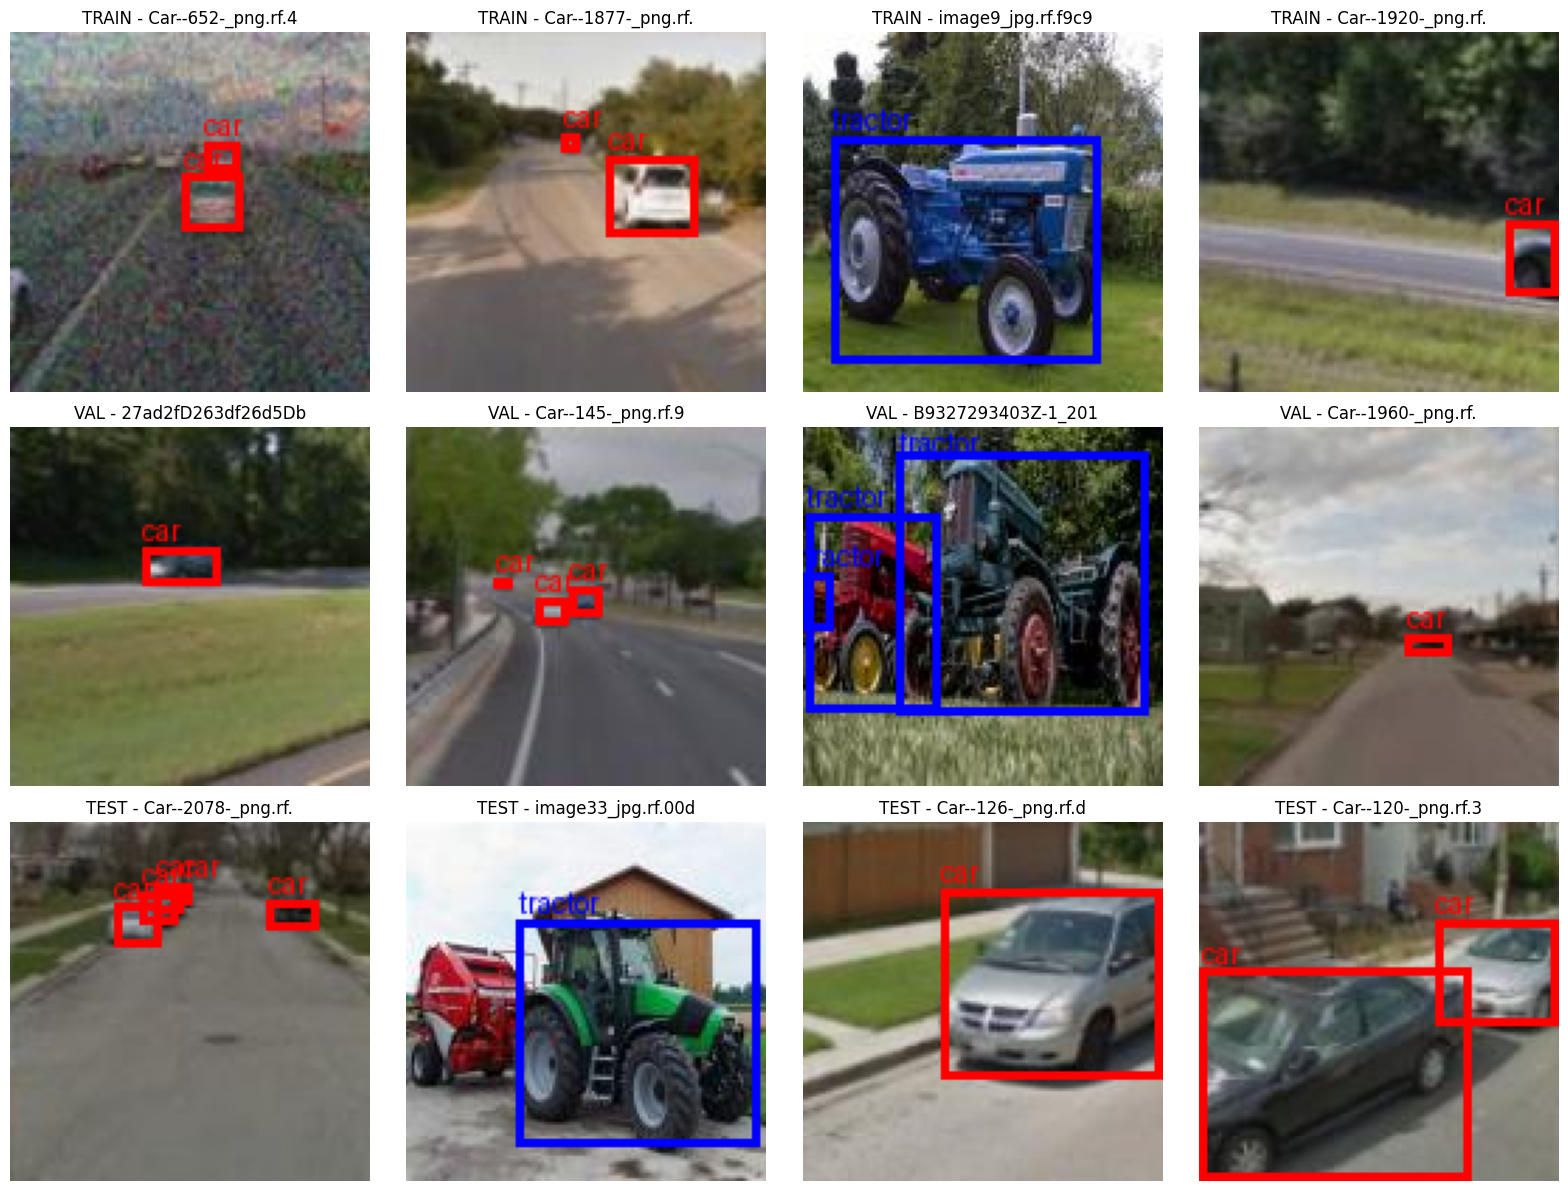

In [36]:
from pathlib import Path
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import random

base = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6")

classes = {
    0: "car",
    1: "tractor"
}

random.seed(42)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for linha, divisao in enumerate(["train", "val", "test"]):

    pasta_imagens = base / "dataset/images" / divisao
    pasta_labels = base / "dataset/labels" / divisao

    imagens = [
        p for p in pasta_imagens.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    selecionadas = random.sample(imagens, min(4, len(imagens)))

    for coluna, imagem_path in enumerate(selecionadas):

        imagem = Image.open(imagem_path).convert("RGB")
        largura, altura = imagem.size

        desenho = ImageDraw.Draw(imagem)

        label_path = pasta_labels / (imagem_path.stem + ".txt")

        if label_path.exists():

            for linha_label in label_path.read_text().splitlines():

                valores = linha_label.strip().split()

                if len(valores) != 5:
                    continue

                classe = int(valores[0])
                x, y, w, h = map(float, valores[1:])

                x1 = (x - w / 2) * largura
                y1 = (y - h / 2) * altura
                x2 = (x + w / 2) * largura
                y2 = (y + h / 2) * altura

                cor = "red" if classe == 0 else "blue"

                desenho.rectangle(
                    [x1, y1, x2, y2],
                    outline=cor,
                    width=3
                )

                desenho.text(
                    (max(0, x1), max(0, y1 - 12)),
                    classes.get(classe, str(classe)),
                    fill=cor
                )

        axes[linha, coluna].imshow(imagem)
        axes[linha, coluna].set_title(
            f"{divisao.upper()} - {imagem_path.name[:18]}"
        )
        axes[linha, coluna].axis("off")

plt.tight_layout()
plt.show()

In [37]:
from pathlib import Path

base = Path("/content/drive/MyDrive/FarmTech_Vision_Fase6")

problemas = []
total_anotacoes = 0

for divisao in ["train", "val", "test"]:

    pasta = base / "dataset/labels" / divisao

    for arquivo in pasta.glob("*.txt"):

        for numero, linha in enumerate(
            arquivo.read_text().splitlines(), start=1
        ):
            try:
                valores = linha.strip().split()

                if len(valores) != 5:
                    raise ValueError("Quantidade incorreta de valores")

                classe = int(valores[0])
                x, y, w, h = map(float, valores[1:])

                if classe not in [0, 1]:
                    raise ValueError("Classe inválida")

                if not (0 <= x <= 1 and 0 <= y <= 1):
                    raise ValueError("Centro fora dos limites")

                if not (0 < w <= 1 and 0 < h <= 1):
                    raise ValueError("Dimensões inválidas")

                if (x - w/2 < 0 or x + w/2 > 1 or
                    y - h/2 < 0 or y + h/2 > 1):
                    raise ValueError("Caixa ultrapassa a imagem")

                total_anotacoes += 1

            except Exception as erro:
                problemas.append(
                    f"{arquivo.name}, linha {numero}: {erro}"
                )

print("Total de anotações válidas:", total_anotacoes)
print("Problemas encontrados:", len(problemas))

for problema in problemas[:20]:
    print(problema)

if not problemas:
    print("VALIDAÇÃO CONCLUÍDA: coordenadas e classes válidas!")

Total de anotações válidas: 134
Problemas encontrados: 0
VALIDAÇÃO CONCLUÍDA: coordenadas e classes válidas!
